# Multimodal Derin Öğrenme Projesi — Aşama 1 (Vize) Analiz Defteri
**Proje:** Trafik İşareti Görüntüleri (RGB) ve Sürücü Uyarı Metinlerinin (Türkçe ADAS) Multimodal Füzyonu ile Sürüş Güvenliği ve Kural İhlali Sınıflandırması  
**Ders:** Derin Öğrenme (Lisans)  
**Kapsam:** Vize Değerlendirme Yönergesindeki 8 kriterin tamamı (Veri Toplama, 1:1 Modalite Eşleştirme, Temizleme & Ön İşleme, 10 EDA Görseli, Sızıntısız Stratified Veri Bölme). *(Not: Model eğitimi final aşamasına aittir.)*

## 1. Ortam Kurulumu, Problem Tanımı ve Multimodal Yapı (10 Puan)
- **Görev Türü:** 4 Ana Sürüş Güvenliği ve Kural İhlali Sınıfına yönelik Çok Sınıflı (Multi-Class) Sınıflandırma (16 temsili GTSRB alt sınıfından türetilmiştir).
- **Modalite 1 (Görsel):** Değişken çözünürlüklü ham RGB trafik işareti görselleri (`20x20`–`112x112` px; ön işleme sonrası `64x64x3` `[0.0, 1.0]`).
- **Modalite 2 (Metin):** Her görselle tekil `sample_id` anahtarı üzerinden eşleşen çeşitlendirilmiş Türkçe ADAS sürücü uyarı metni, kural tanımı ve sensör koşul bağlamı.
- **Neden Multimodal?** Gece/düşük ışık veya `20–31px` düşük çözünürlükte şekil/rakam karışıklığını önlemek için görsel öznitelikler metinsel kural/bağlam temsiliyle ortak uzayda birleştirilir.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image as IPyImage, display

# Proje kök dizinini bul (hem notebooks/ hem kök dizinden çalıştırılabilir)
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    FIGURES_DIR,
    IMAGE_SIZE,
    MIN_SAMPLES_PER_CLASS,
    MIN_TOTAL_SAMPLES,
    PROCESSED_DATA_DIR,
    RANDOM_SEED,
    REPORTS_DIR,
    SAFETY_CATEGORIES,
    SIGN_CATALOG,
    SPLIT_RATIOS,
)

# Tüm hattı sıfırdan yeniden üretmek için True yapılabilir (mevcut çıktıları hızlıca incelemek için False)
FORCE_REBUILD = False

print(f"Proje Kök Dizini : {PROJECT_ROOT}")
print(f"RANDOM_SEED      : {RANDOM_SEED}")
print(f"Hedef Görsel Boy : {IMAGE_SIZE}")
print(f"Bölme Oranları   : {SPLIT_RATIOS}")

catalog_df = pd.DataFrame.from_dict(SIGN_CATALOG, orient="index")[
    ["gtsrb_id", "code_name", "turkish_name", "safety_class_id", "safety_class_name", "risk_level"]
].reset_index(drop=True)
display(catalog_df)

Proje Kök Dizini : C:\Users\ferhat\Desktop\github_projeler\cok-modlu-tabela
RANDOM_SEED      : 42
Hedef Görsel Boy : (64, 64)
Bölme Oranları   : {'train': 0.7, 'val': 0.15, 'test': 0.15}


,gtsrb_id,code_name,turkish_name,safety_class_id,safety_class_name,risk_level
0,1,Hiz_Siniri_30,Azami Hız Sınırı 30 km/sa,0,Kritik_Yasak_ve_Hiz,Çok Yüksek
1,2,Hiz_Siniri_50,Azami Hız Sınırı 50 km/sa,0,Kritik_Yasak_ve_Hiz,Yüksek
2,4,Hiz_Siniri_70,Azami Hız Sınırı 70 km/sa,0,Kritik_Yasak_ve_Hiz,Yüksek
3,9,Gecme_Yasagi,Öndeki Aracı Geçmek Yasaktır,0,Kritik_Yasak_ve_Hiz,Çok Yüksek
4,17,Girisi_Olmayan_Yol,Girişi Olmayan Yol (Tek Yön İhlali),0,Kritik_Yasak_ve_Hiz,Çok Yüksek
5,12,Oncelikli_Yol,Ana Yol / Öncelikli Yol,1,Oncelik_ve_Durdurma,Yüksek
6,13,Yol_Ver,Yol Ver,1,Oncelik_ve_Durdurma,Çok Yüksek
7,14,Dur,DUR (Tam Durma Zorunluluğu),1,Oncelik_ve_Durdurma,Çok Yüksek
8,18,Dikkat_Tehlike,Dikkat (Genel Tehlike Uyarısı),2,Tehlike_ve_Uyari,Orta-Yüksek
9,25,Yol_Calismasi,Yol Çalışması,2,Tehlike_ve_Uyari,Orta-Yüksek


## 2. Veri Kaynakları, Toplama Süreci ve 1:1 Modalite Eşleştirme (10 + 15 Puan)
- **Görsel Kaynak:** GTSRB (German Traffic Sign Recognition Benchmark) şemasından seçilen 16 sınıf (`src/data_loader.py` hem resmi arşiv indirmeyi hem de deterministik gerçekçi üretimi destekler).
- **Eşleştirme Anahtarı:** Görsel tablosu (`raw_images_manifest.csv`) ve metin tablosu (`raw_driver_warnings.csv`) **`sample_id` (`TRSIGN_00001`..)** üzerinden tekilleştirilip `validate="one_to_one"` ile inner join edilir.

In [2]:
from src.data_loader import MATCHED_DATASET_PATH, STEP2_REPORT_PATH, run_step2_pipeline

if FORCE_REBUILD or not MATCHED_DATASET_PATH.exists() or not STEP2_REPORT_PATH.exists():
    raw_matched_df, step2_report = run_step2_pipeline(prefer_download=False, overwrite=FORCE_REBUILD)
else:
    raw_matched_df = pd.read_csv(MATCHED_DATASET_PATH, encoding="utf-8")
    with open(STEP2_REPORT_PATH, "r", encoding="utf-8") as f:
        step2_report = json.load(f)

print("Adım 2 Doğrulama Özeti:")
print(json.dumps(step2_report, ensure_ascii=False, indent=2))
display(
    raw_matched_df[
        ["sample_id", "gtsrb_id", "sign_code", "safety_class_name", "width", "height", "lighting_condition", "word_count"]
    ].head(5)
)

Adım 2 Doğrulama Özeti:
{
  "raw_image_records": 2993,
  "unique_image_records": 2975,
  "duplicate_image_ids": 18,
  "raw_text_records": 2985,
  "unique_text_records": 2971,
  "duplicate_text_ids": 14,
  "matched_multimodal_samples": 2960,
  "unmatched_image_only_count": 15,
  "unmatched_text_only_count": 11,
  "total_unique_candidate_pairs": 2986,
  "matching_rate_pct": 99.13,
  "quality_issues_detected_for_step3": {
    "corrupted_or_missing_images": 12,
    "ultra_low_res_images_lt20px": 16,
    "missing_or_empty_texts": 10,
    "raw_label_consistency_mismatches": 10,
    "noisy_log_tagged_texts": 1226
  },
  "num_safety_classes": 4,
  "safety_class_distribution": {
    "Kritik_Yasak_ve_Hiz": 980,
    "Oncelik_ve_Durdurma": 560,
    "Tehlike_ve_Uyari": 705,
    "Mecburi_Yon_ve_Bilgi": 715
  },
  "min_safety_class_count": 560,
  "num_gtsrb_subclasses": 16,
  "min_subclass_count": 160,
  "course_criteria_check": {
    "min_3_classes_ok": true,
    "min_150_per_safety_class_ok": true,

,sample_id,gtsrb_id,sign_code,safety_class_name,width,height,lighting_condition,word_count
0,TRSIGN_00001,1,Hiz_Siniri_30,Kritik_Yasak_ve_Hiz,67,72,Normal Gün Işığı,36
1,TRSIGN_00002,1,Hiz_Siniri_30,Kritik_Yasak_ve_Hiz,33,30,Normal Gün Işığı,39
2,TRSIGN_00003,1,Hiz_Siniri_30,Kritik_Yasak_ve_Hiz,56,61,Normal Gün Işığı,38
3,TRSIGN_00004,1,Hiz_Siniri_30,Kritik_Yasak_ve_Hiz,36,36,Normal Gün Işığı,36
4,TRSIGN_00005,1,Hiz_Siniri_30,Kritik_Yasak_ve_Hiz,104,104,Normal Gün Işığı,38


## 3. Veri Temizleme, Ön İşleme ve Öncesi–Sonrası Karşılaştırmaları (15 Puan)
- **Temizlik & Etiket Onarımı:** `18` görsel + `14` metin tekrar kaydı ve `26` eksik modaliteli kayıt eşleştirme aşamasında ayrılmış; `10` ham sınıf etiket hatası `SIGN_CATALOG` ile düzeltilmiş; `12` bozuk görsel + `16` `<20px` görsel + `10` boş metin elenerek **`2.922` temiz örnek** elde edilmiştir.
- **Görsel Ön İşleme:** `64x64 Bicubic` boyutlandırma + yalnızca LAB `L` kanalında `CLAHE` + `[0.0, 1.0]` `float32` normalizasyon.
- **Metin Ön İşleme:** CAN-BUS/sensör etiketlerinin silinmesi, Türkçe duyarlı küçük harf dönüşümü (`İ->i`, `I->ı`), hız limitleri korunarak noktalama/stop-word temizliği, `537` kelimelik sözlük ve `MAX_SEQ_LEN=40` (`%0.0` kesilme kaybı).

Öncesi–Sonrası Sayısal Karşılaştırma Tablosu:


,Kategori,Metrik,Islem_Oncesi,Islem_Sonrasi,Etki_Aciklamasi
0,Veri Miktarı,Eşleşmiş Örnek Sayısı,2960,2922,38 bozuk/boş/<20px kayıt elendi
1,Etiket Kalitesi,Tutarsız Ham Etiket,10,0,SIGN_CATALOG referansına göre doğrulandı
2,Görsel Modalite,Çözünürlük Aralığı (px),14px – 112px (Değişken),64x64 (Sabit),Bicubic interpolasyonla ortak CNN giriş boyutu...
3,Görsel Modalite,Piksel Değer Aralığı,"[0, 255] uint8","[0.0, 1.0] float32",Tüm kanallar birim aralığa normalize edildi
4,Görsel Modalite,Ortalama Parlaklık (0–255),113.46 ± 26.19,139.28 ± 24.00,LAB-CLAHE ile düşük ışık ve parlama dengelendi
5,Görsel Modalite,Ortalama Kontrast Std,59.35 ± 12.78,61.39 ± 7.43,Yerel kenar ve rakam ayırt ediciliği artırıldı
6,Metin Modalitesi,Log/Noktalama Gürültülü Kayıt (%),%41.51,%0.0,CAN-BUS etiketleri ve fazla noktalama temizlendi
7,Metin Modalitesi,Ortalama Karakter Uzunluğu,255.1,224.6,Anlamsız ek/bağlaç temizliğiyle kompakt temsil
8,Metin Modalitesi,Ortalama Kelime / Token Sayısı,33.7,31.6,Sözlük=537 token; max_len=40 kesme=%0.0


Ders Yeterlilik Kontrolleri: {'safety_class_distribution': {'Kritik_Yasak_ve_Hiz': 968, 'Oncelik_ve_Durdurma': 548, 'Tehlike_ve_Uyari': 698, 'Mecburi_Yon_ve_Bilgi': 708}, 'min_safety_class_count': 548, 'min_subclass_count': 159, 'total_clean_samples': 2922, 'meets_min_3_classes': True, 'meets_150_per_safety_class': True, 'meets_150_per_subclass': True, 'meets_500_total': True}


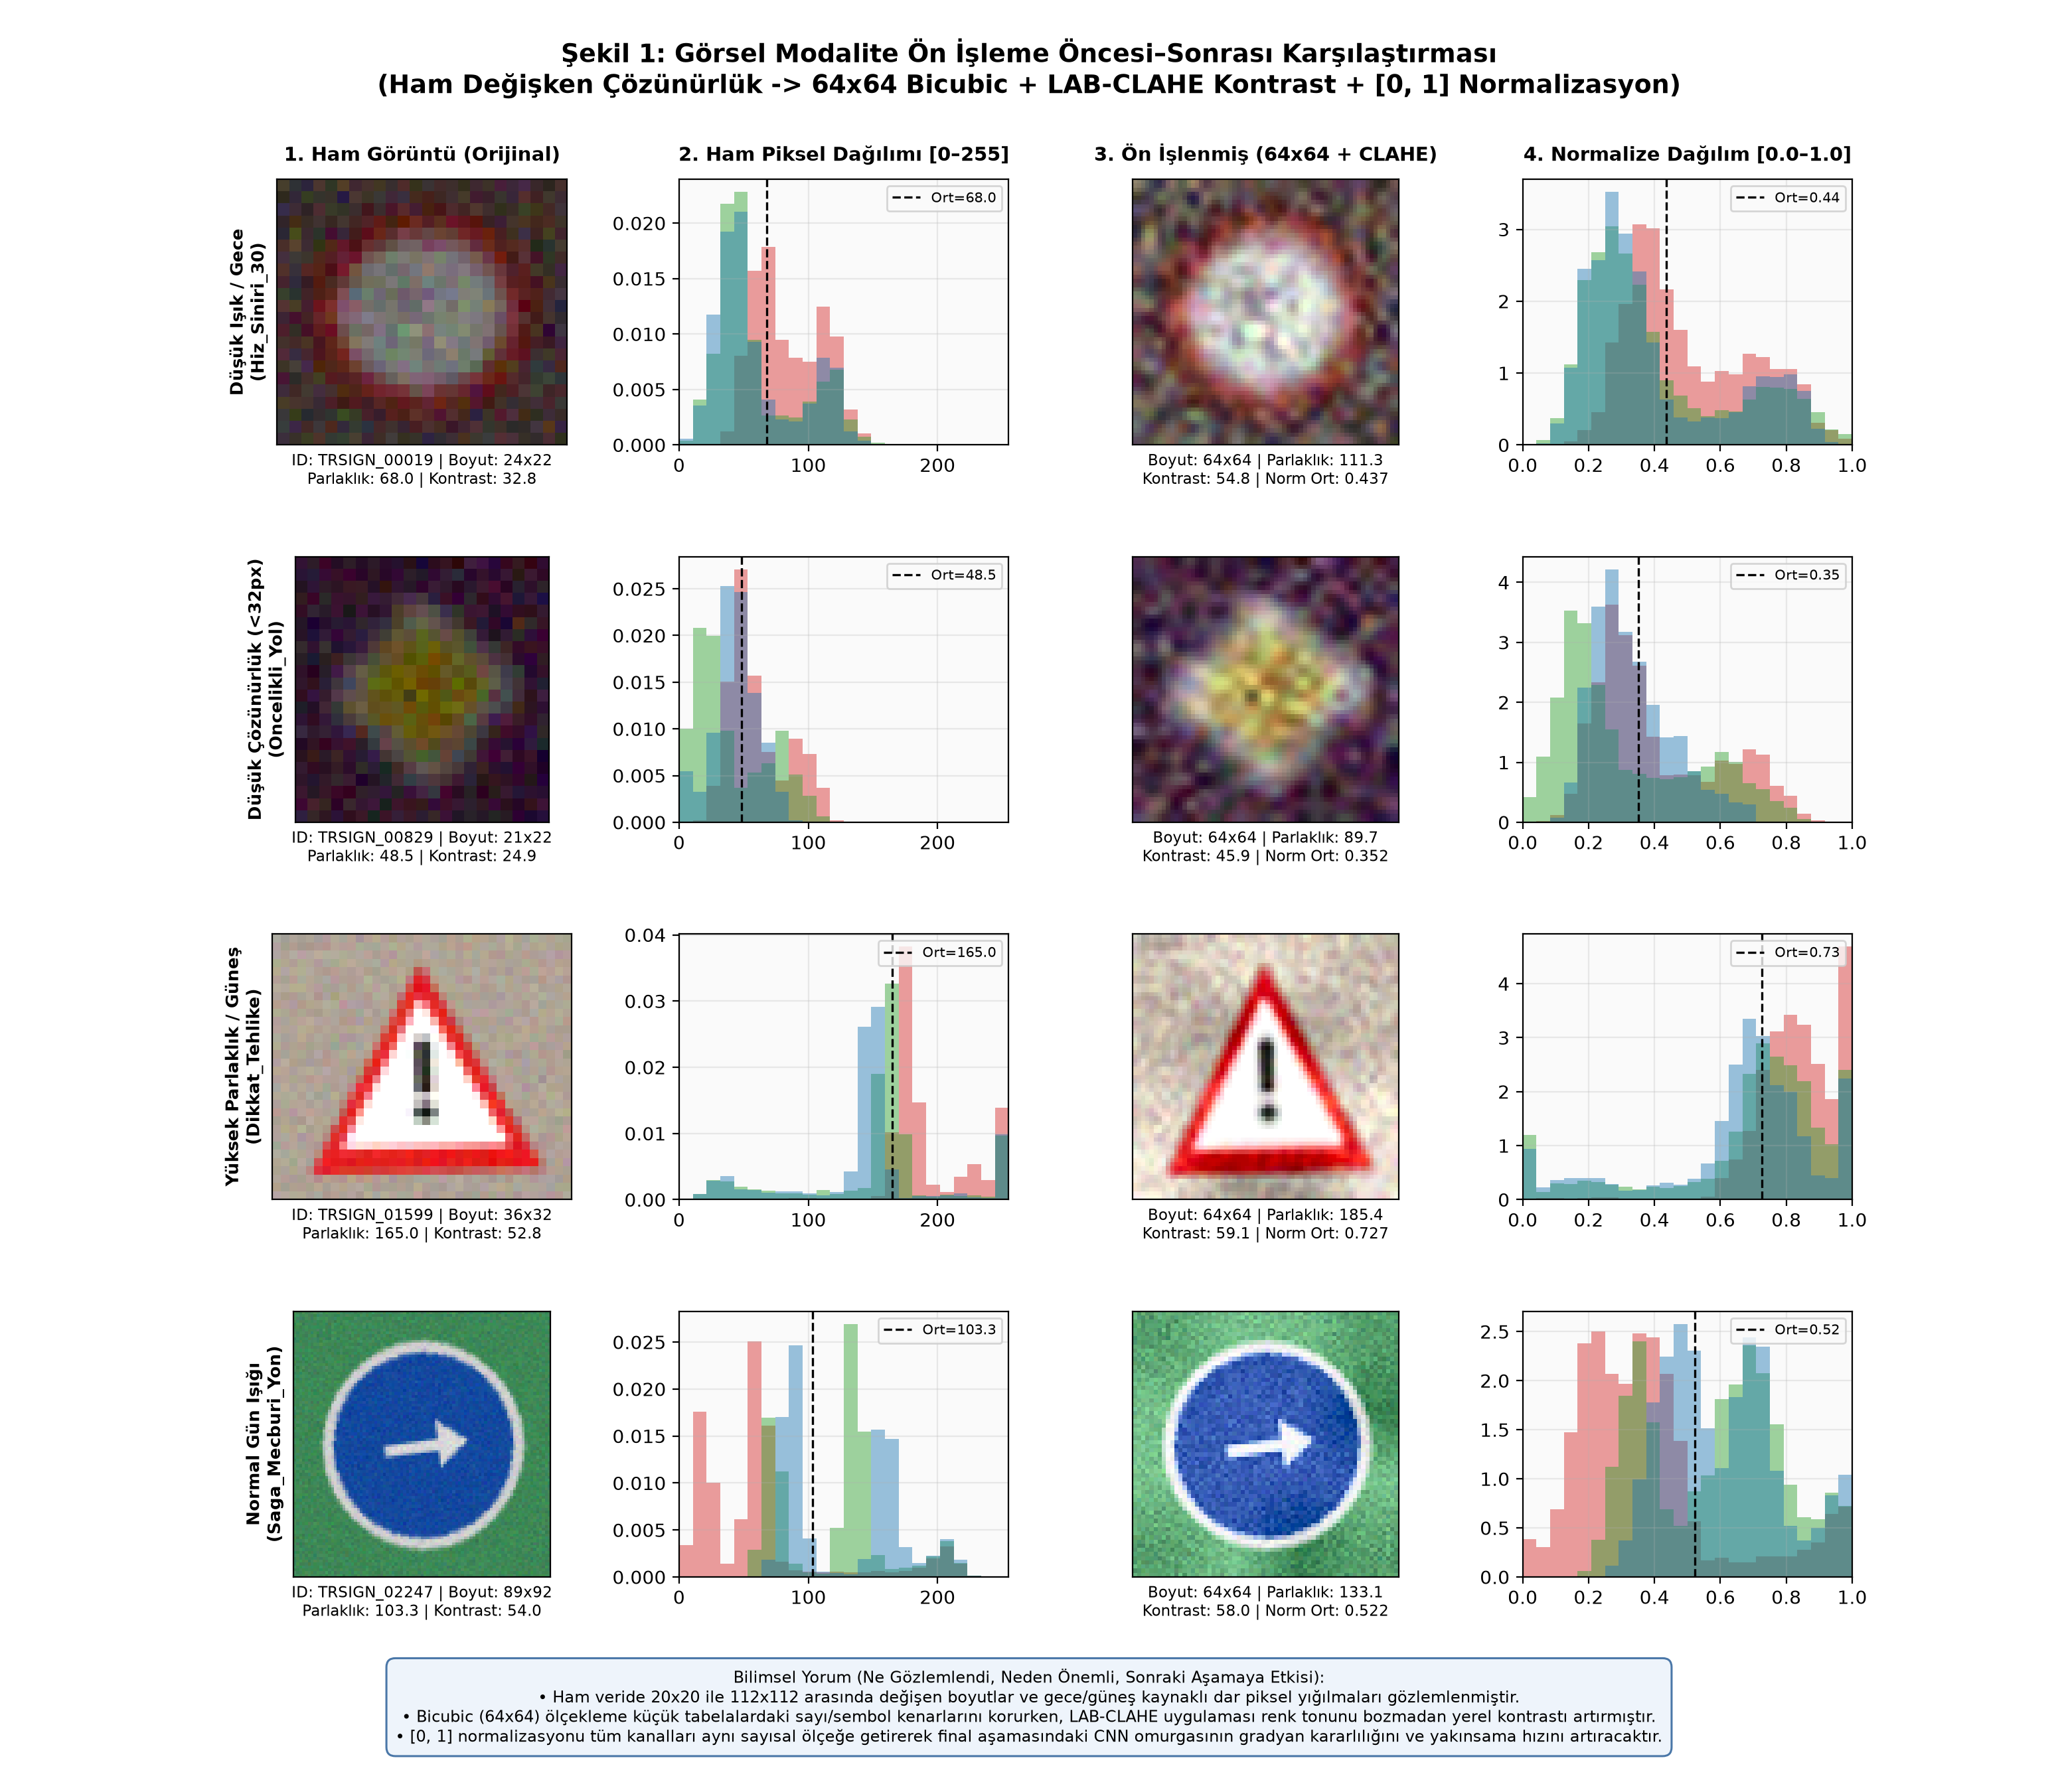

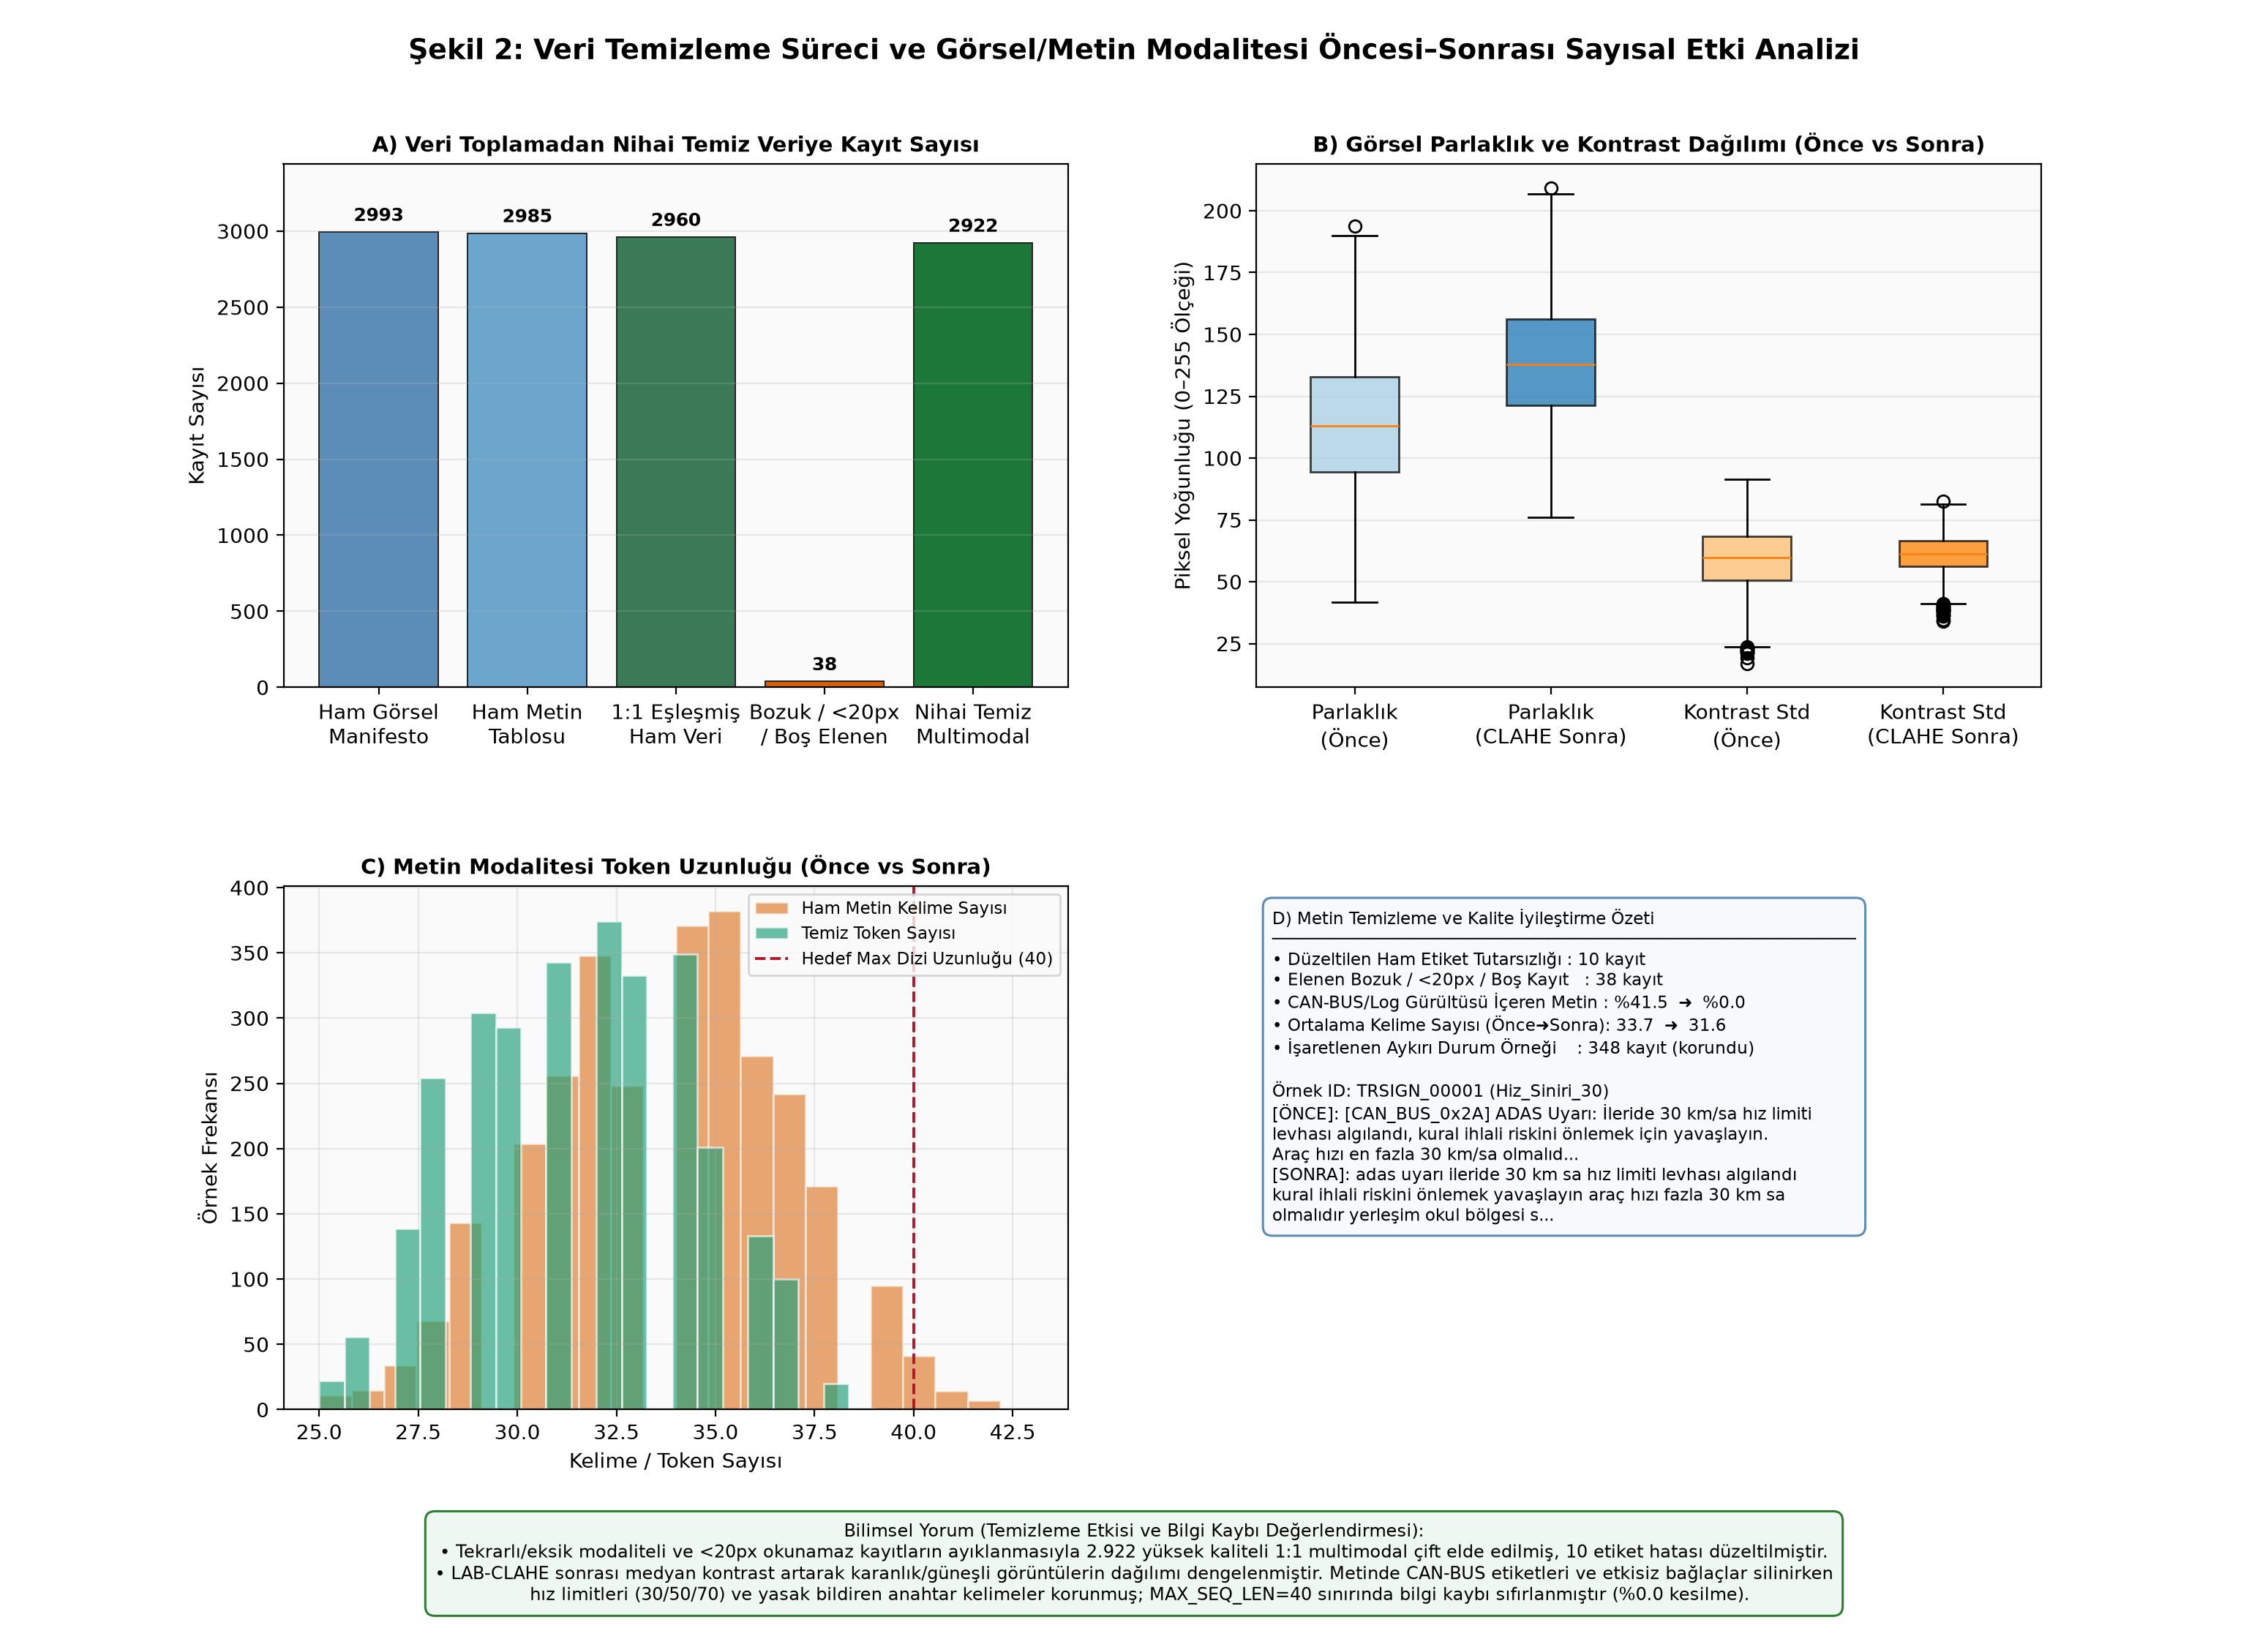

In [3]:
from src.preprocessing import (
    BEFORE_AFTER_SUMMARY_PATH,
    CLEANED_DATASET_PATH,
    FIG01_IMAGE_BEFORE_AFTER_PATH,
    FIG02_TEXT_CLEANING_BEFORE_AFTER_PATH,
    STEP3_REPORT_PATH,
    run_step3_pipeline,
)

if FORCE_REBUILD or not CLEANED_DATASET_PATH.exists() or not FIG01_IMAGE_BEFORE_AFTER_PATH.exists():
    cleaned_df, before_after_df, step3_report = run_step3_pipeline(save_sample_pngs=True)
else:
    cleaned_df = pd.read_csv(CLEANED_DATASET_PATH, encoding="utf-8")
    before_after_df = pd.read_csv(BEFORE_AFTER_SUMMARY_PATH, encoding="utf-8")
    with open(STEP3_REPORT_PATH, "r", encoding="utf-8") as f:
        step3_report = json.load(f)

print("Öncesi–Sonrası Sayısal Karşılaştırma Tablosu:")
display(before_after_df)
print("Ders Yeterlilik Kontrolleri:", step3_report["post_cleaning_criteria_check"])

display(IPyImage(filename=str(FIG01_IMAGE_BEFORE_AFTER_PATH)))
display(IPyImage(filename=str(FIG02_TEXT_CLEANING_BEFORE_AFTER_PATH)))

## 4. Keşifsel Veri Analizi (EDA), İstatistikler ve Görselleştirme (12 + 25 Puan)
Aşağıdaki hücre genel veri seti ve 4 ana sınıf için özet istatistikleri (`step4_statistical_summary.csv`) sunar ve vize yönergesindeki tüm modalite, sınıf dengesizliği, çapraz ilişki, füzyon uzayı ve aykırı durum grafiklerini (`Şekil 3`–`Şekil 9`) görüntüler.

Genel Veri Seti Özet İstatistikleri (N=2.922):


,Kapsam,Degisken,Ornek_Sayisi,Ortalama,Std_Sapma,Medyan,Q25,Q75,IQR,Min,Max
0,GENEL_TUM_VERI,width,2922,66.86,23.47,67.00,47.00,87.00,40.00,21.00,107.00
1,GENEL_TUM_VERI,height,2922,66.87,23.71,67.00,48.00,87.00,39.00,20.00,112.00
2,GENEL_TUM_VERI,resolution_area,2922,5021.04,3163.01,4485.00,2209.00,7569.00,5360.00,420.00,11984.00
3,GENEL_TUM_VERI,mean_brightness,2922,113.46,26.19,113.00,94.36,132.71,38.36,41.88,193.65
4,GENEL_TUM_VERI,contrast_std,2922,59.35,12.78,59.84,50.47,68.31,17.84,16.95,91.31
5,GENEL_TUM_VERI,mean_brightness_after,2922,139.28,24.00,137.95,121.35,156.31,34.96,76.11,209.31
6,GENEL_TUM_VERI,contrast_std_after,2922,61.39,7.43,61.27,56.35,66.52,10.17,33.90,82.65
7,GENEL_TUM_VERI,char_length,2922,255.04,22.14,255.00,238.00,270.00,32.00,196.00,327.00
8,GENEL_TUM_VERI,word_count,2922,33.70,3.09,34.00,31.25,36.00,4.75,25.00,43.00
9,GENEL_TUM_VERI,clean_char_length,2922,224.60,18.48,224.00,211.00,237.00,26.00,180.00,275.00


Silhouette Skorları: {'silhouette_visual': 0.197, 'silhouette_text': 0.2374, 'silhouette_fused': 0.211}


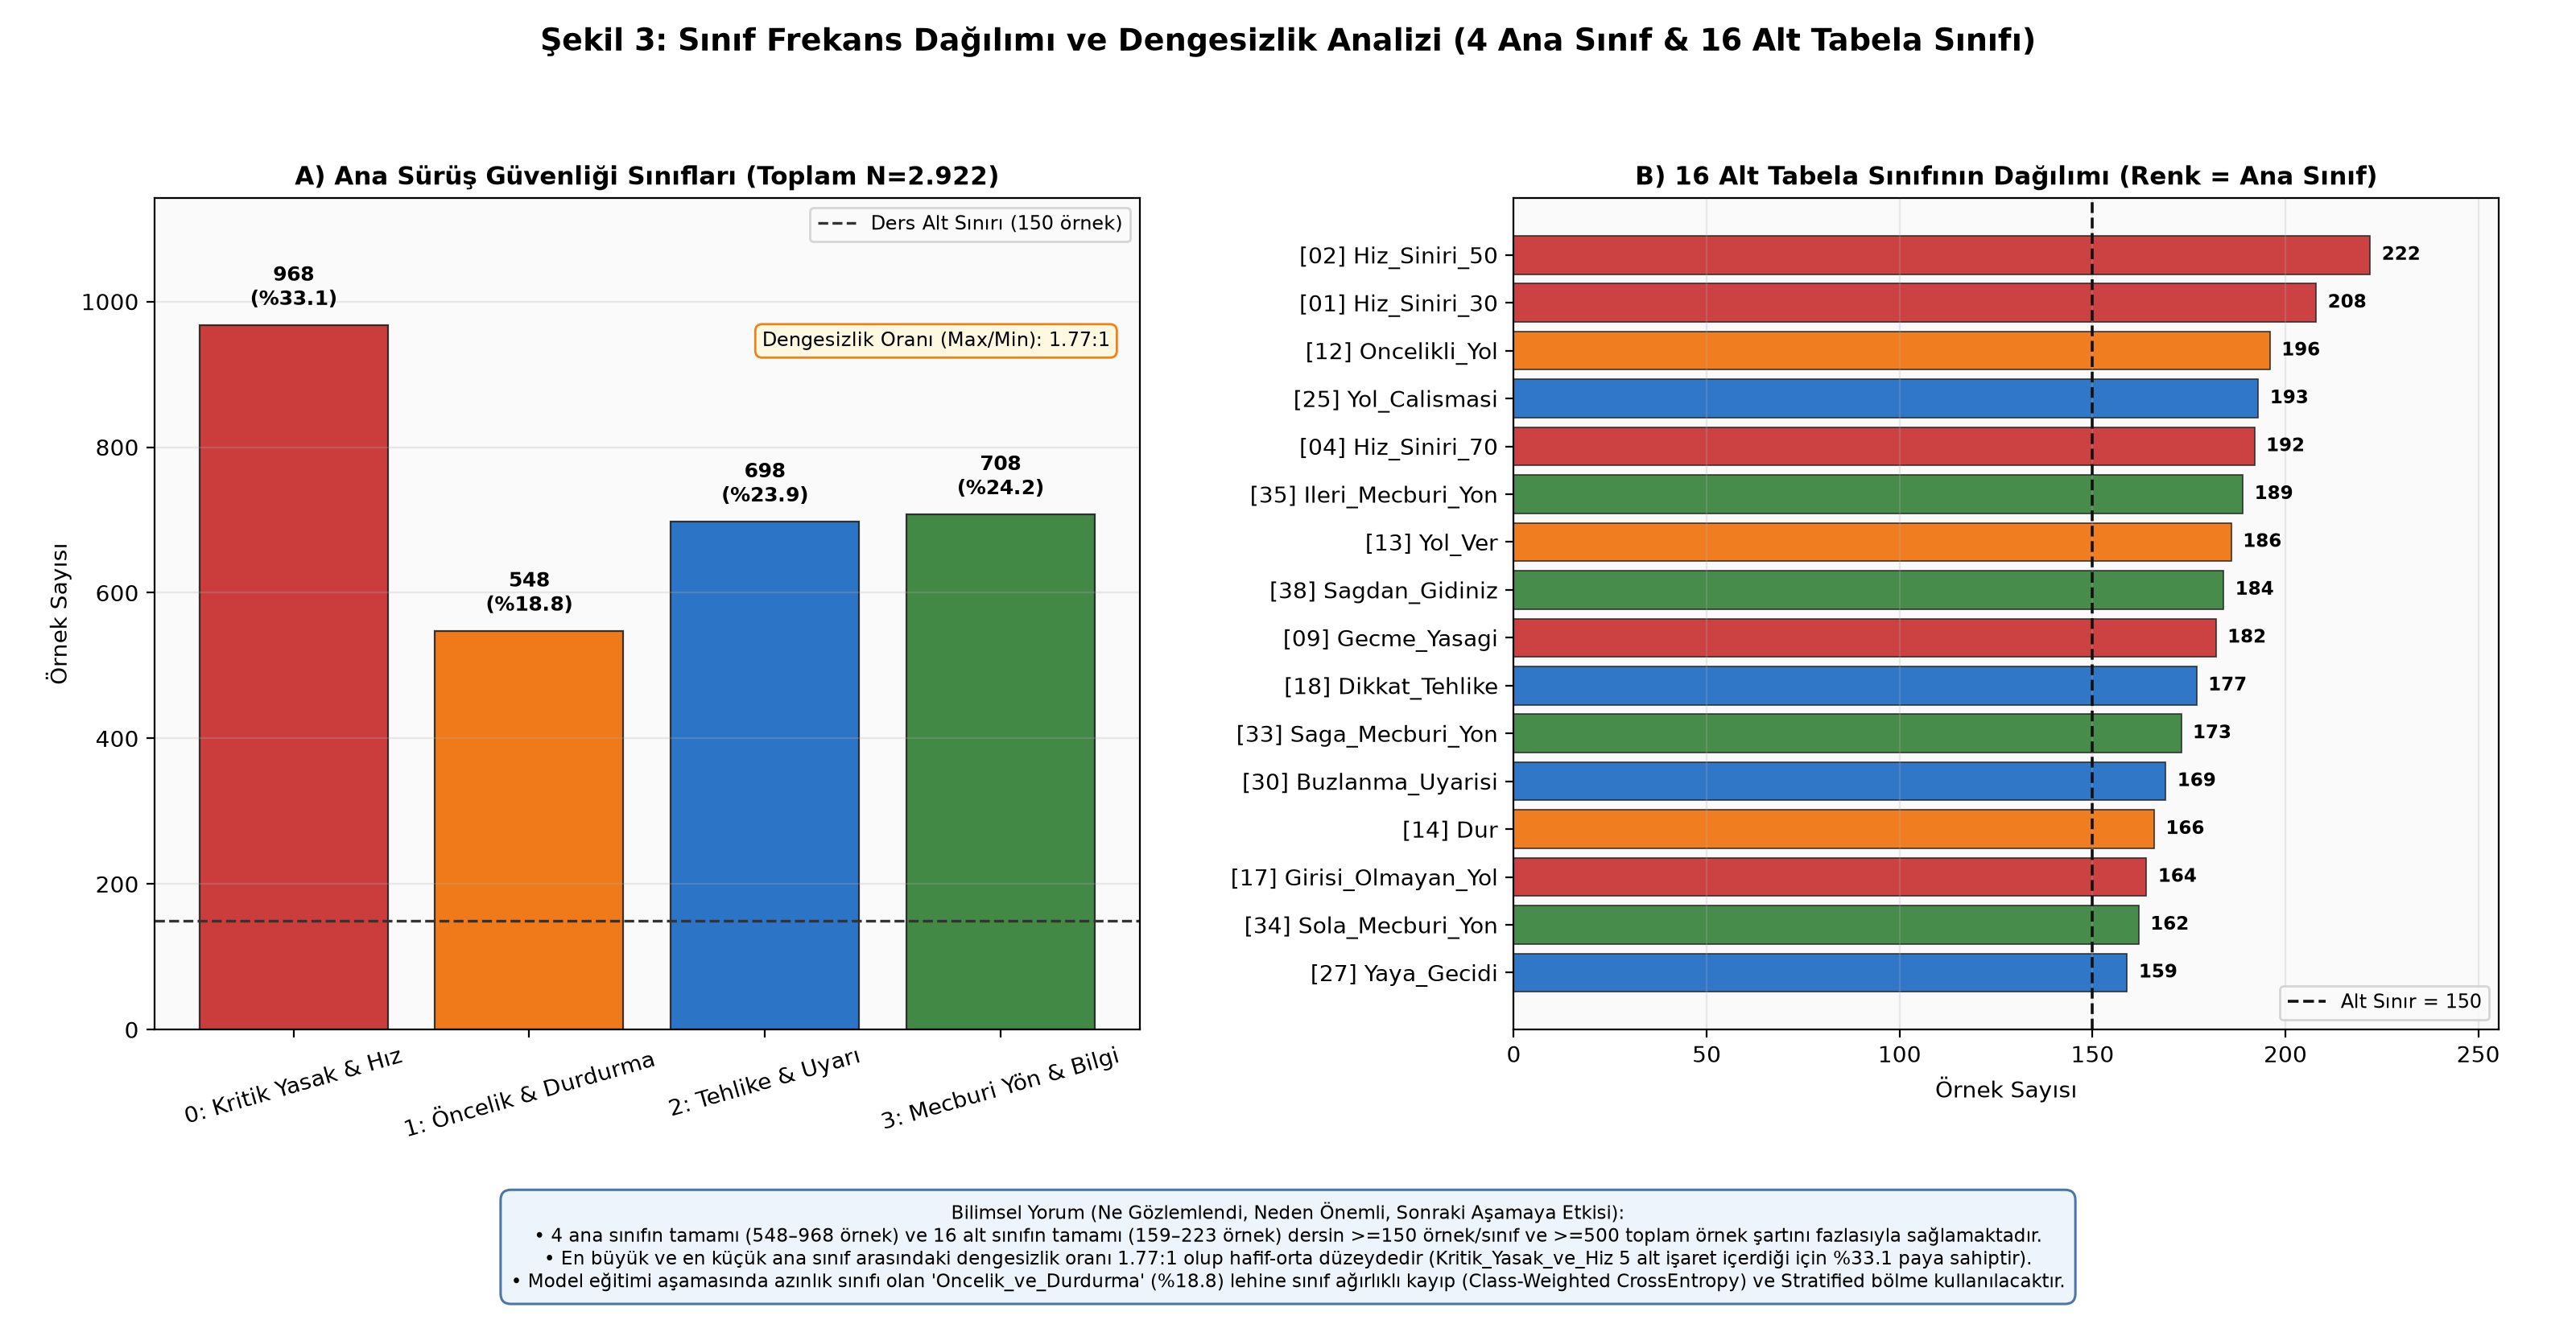

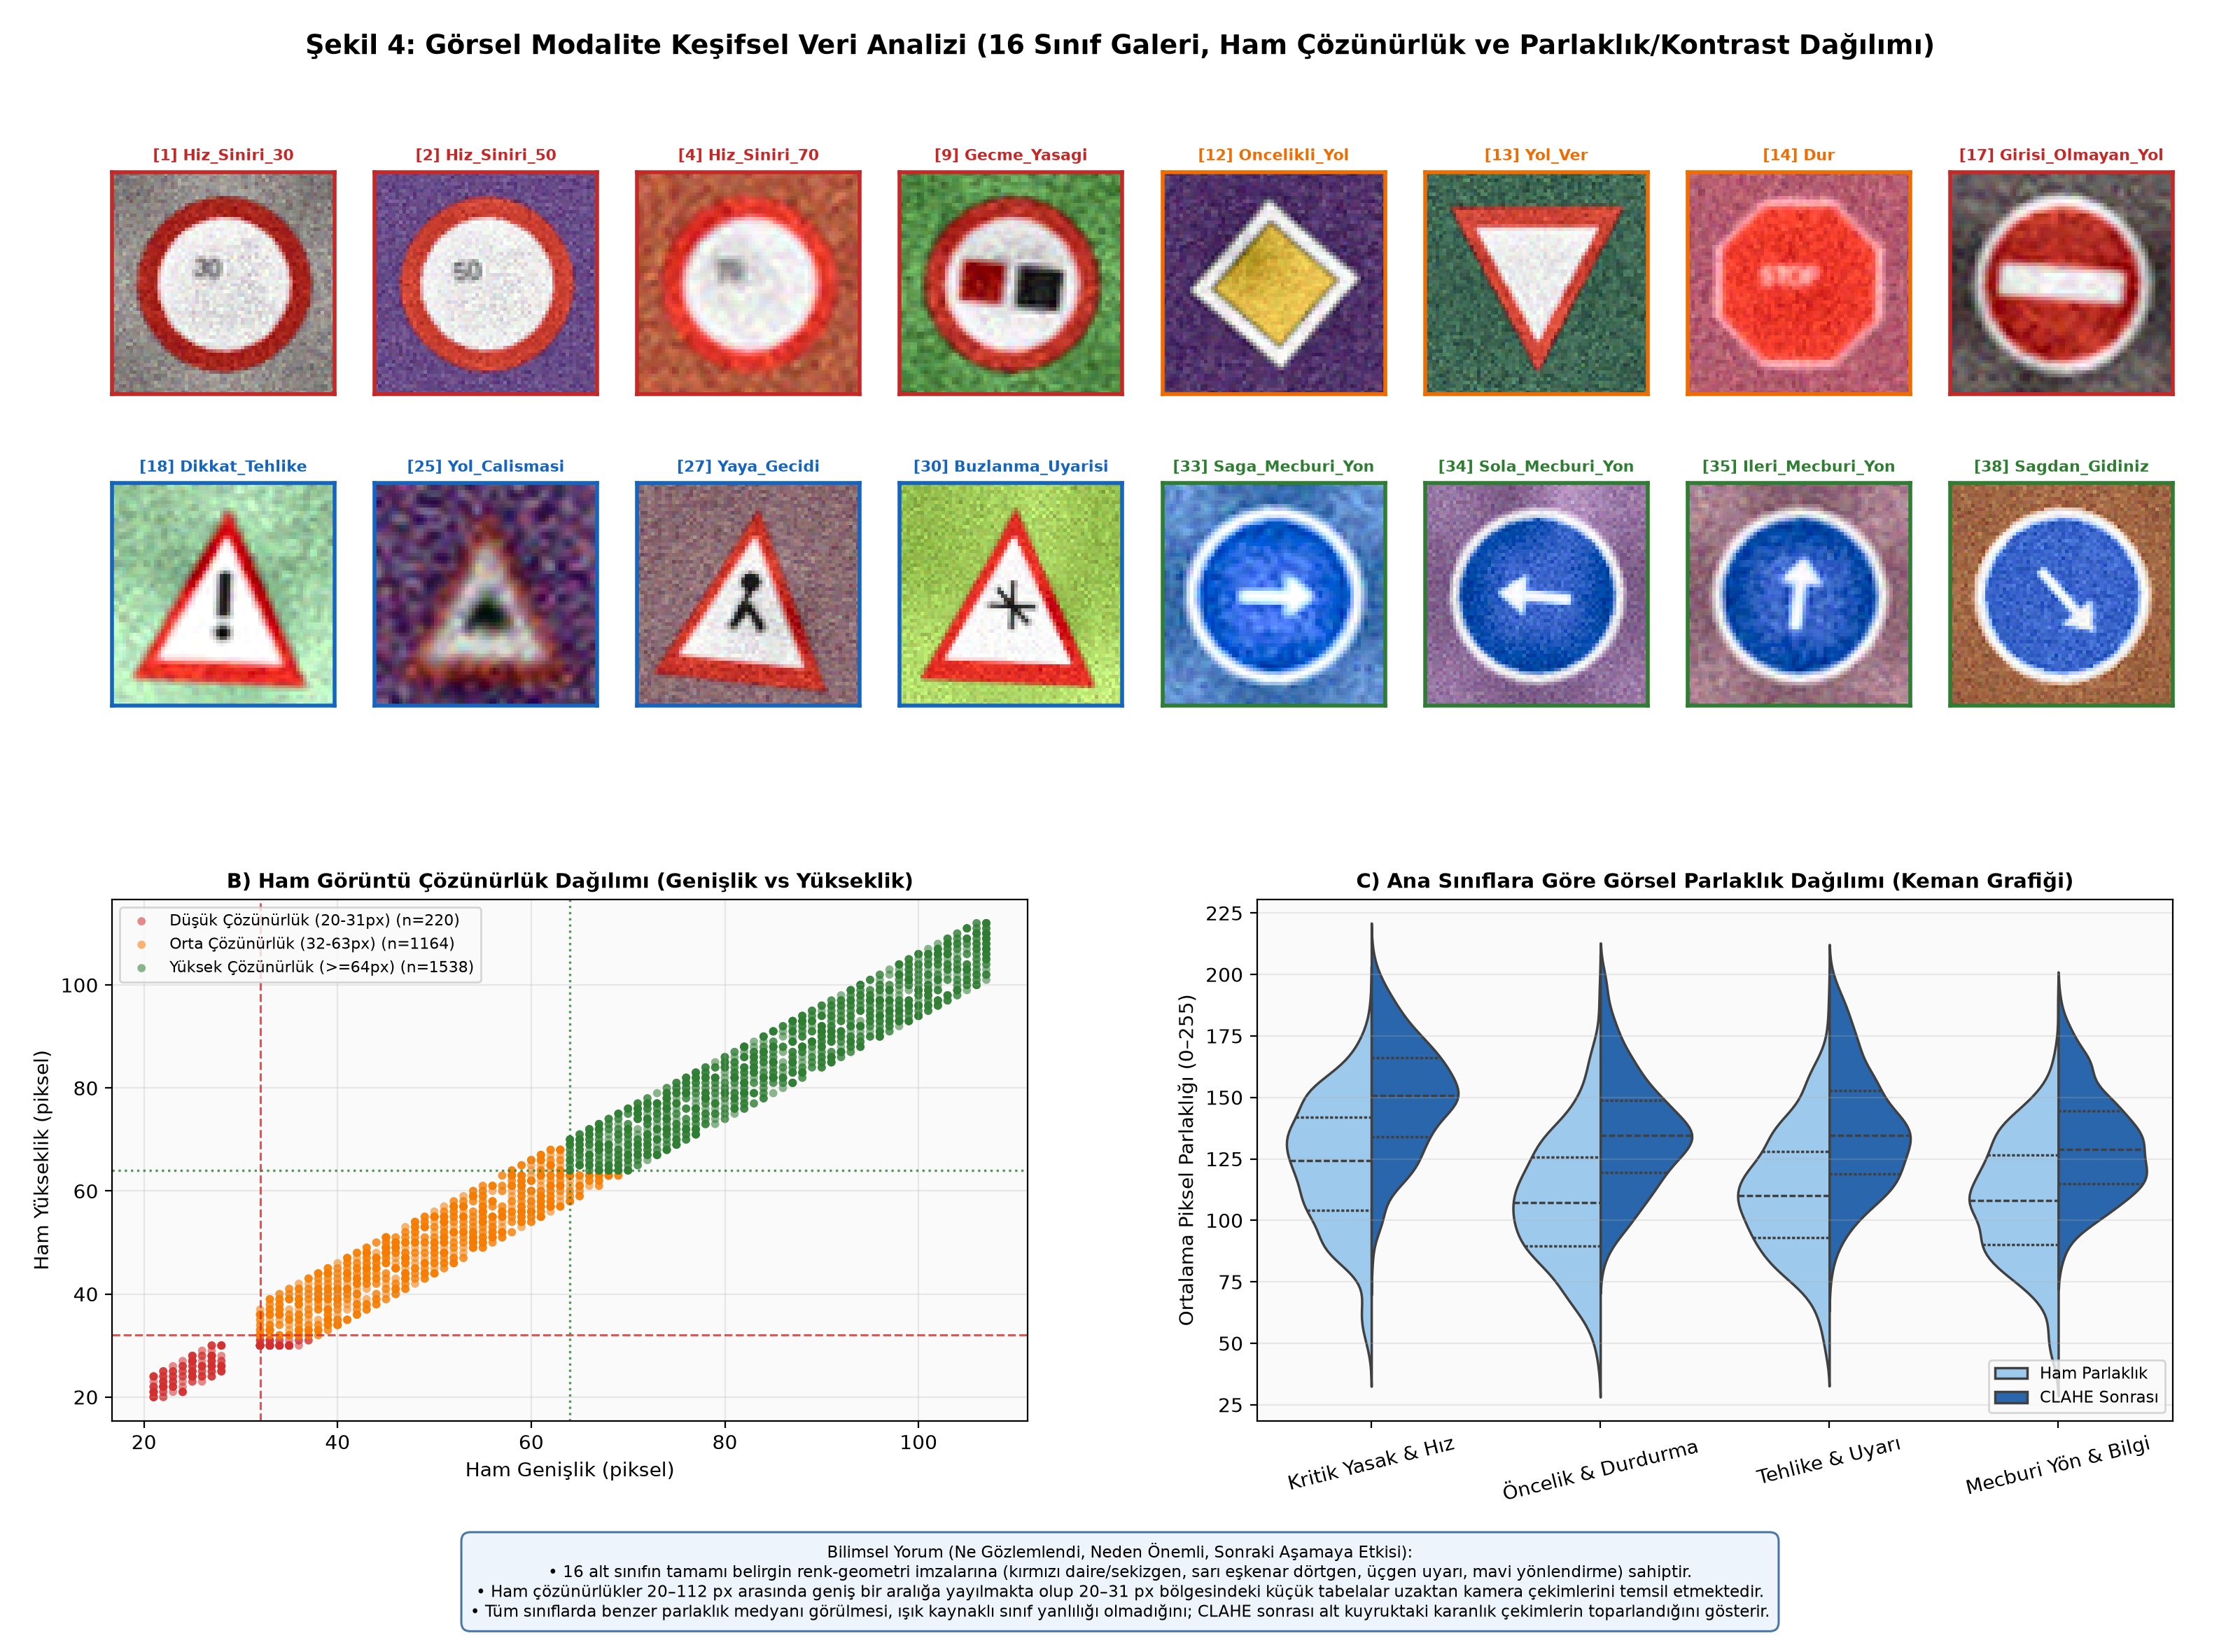

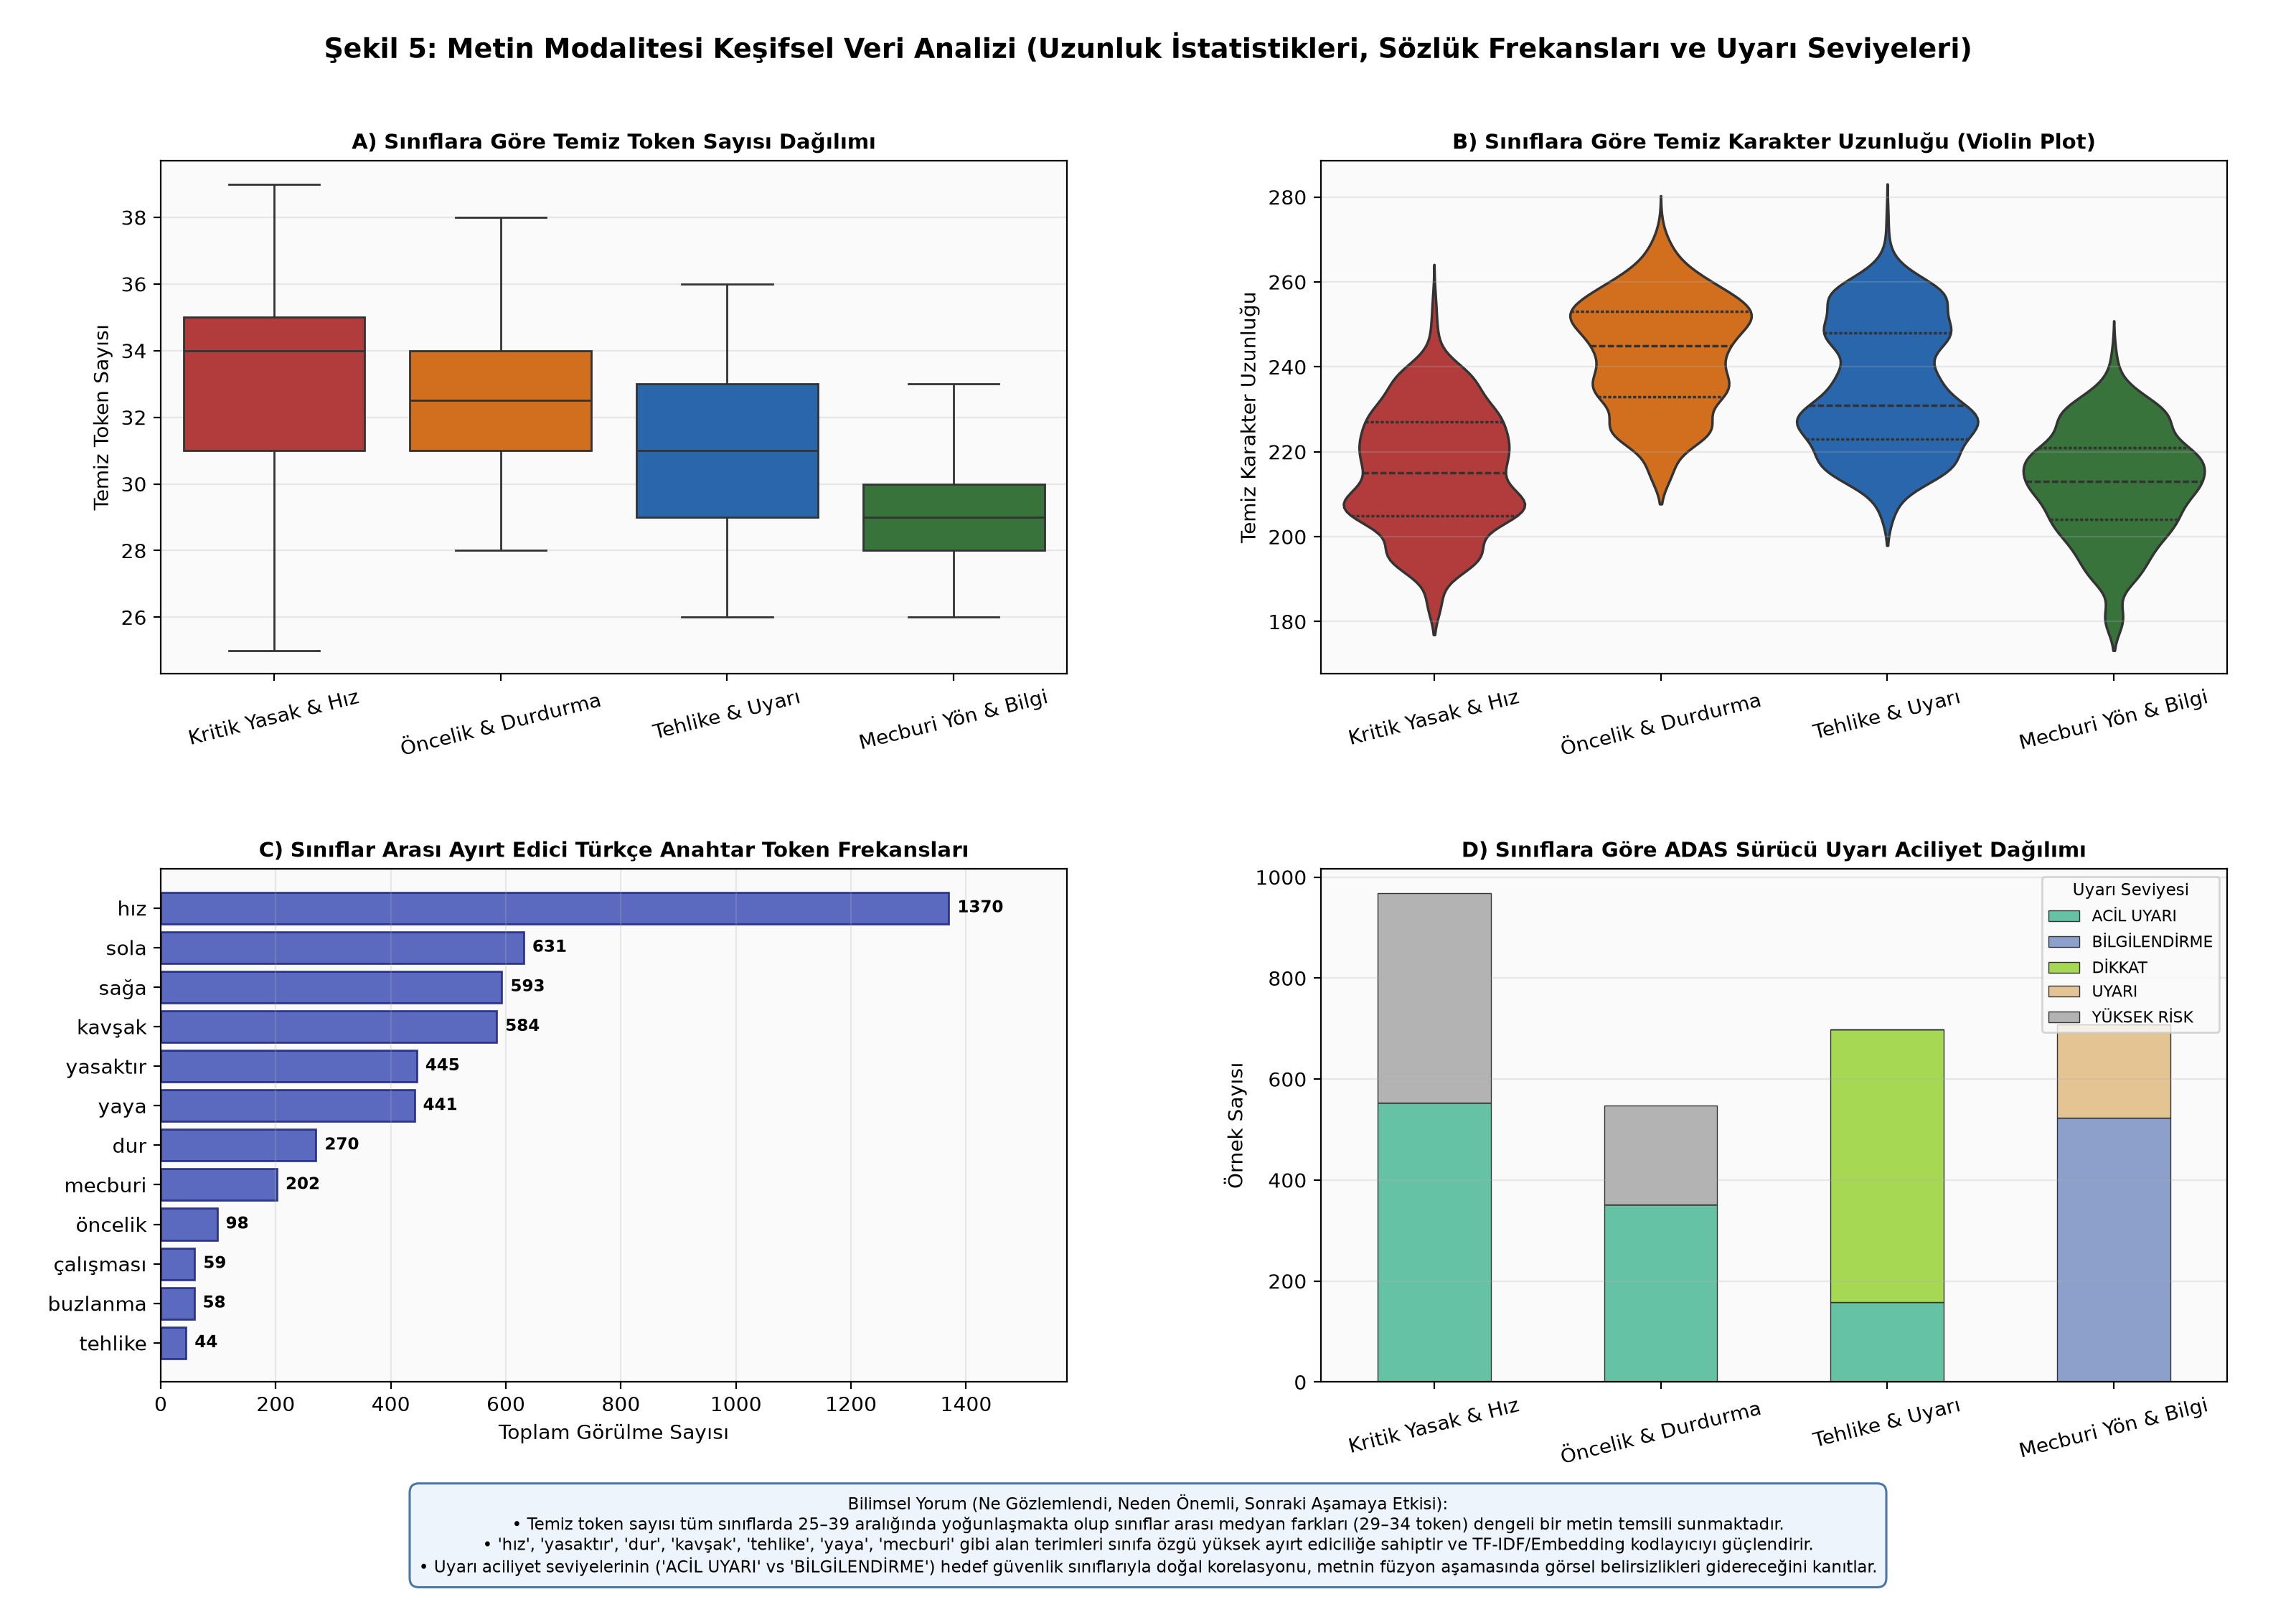

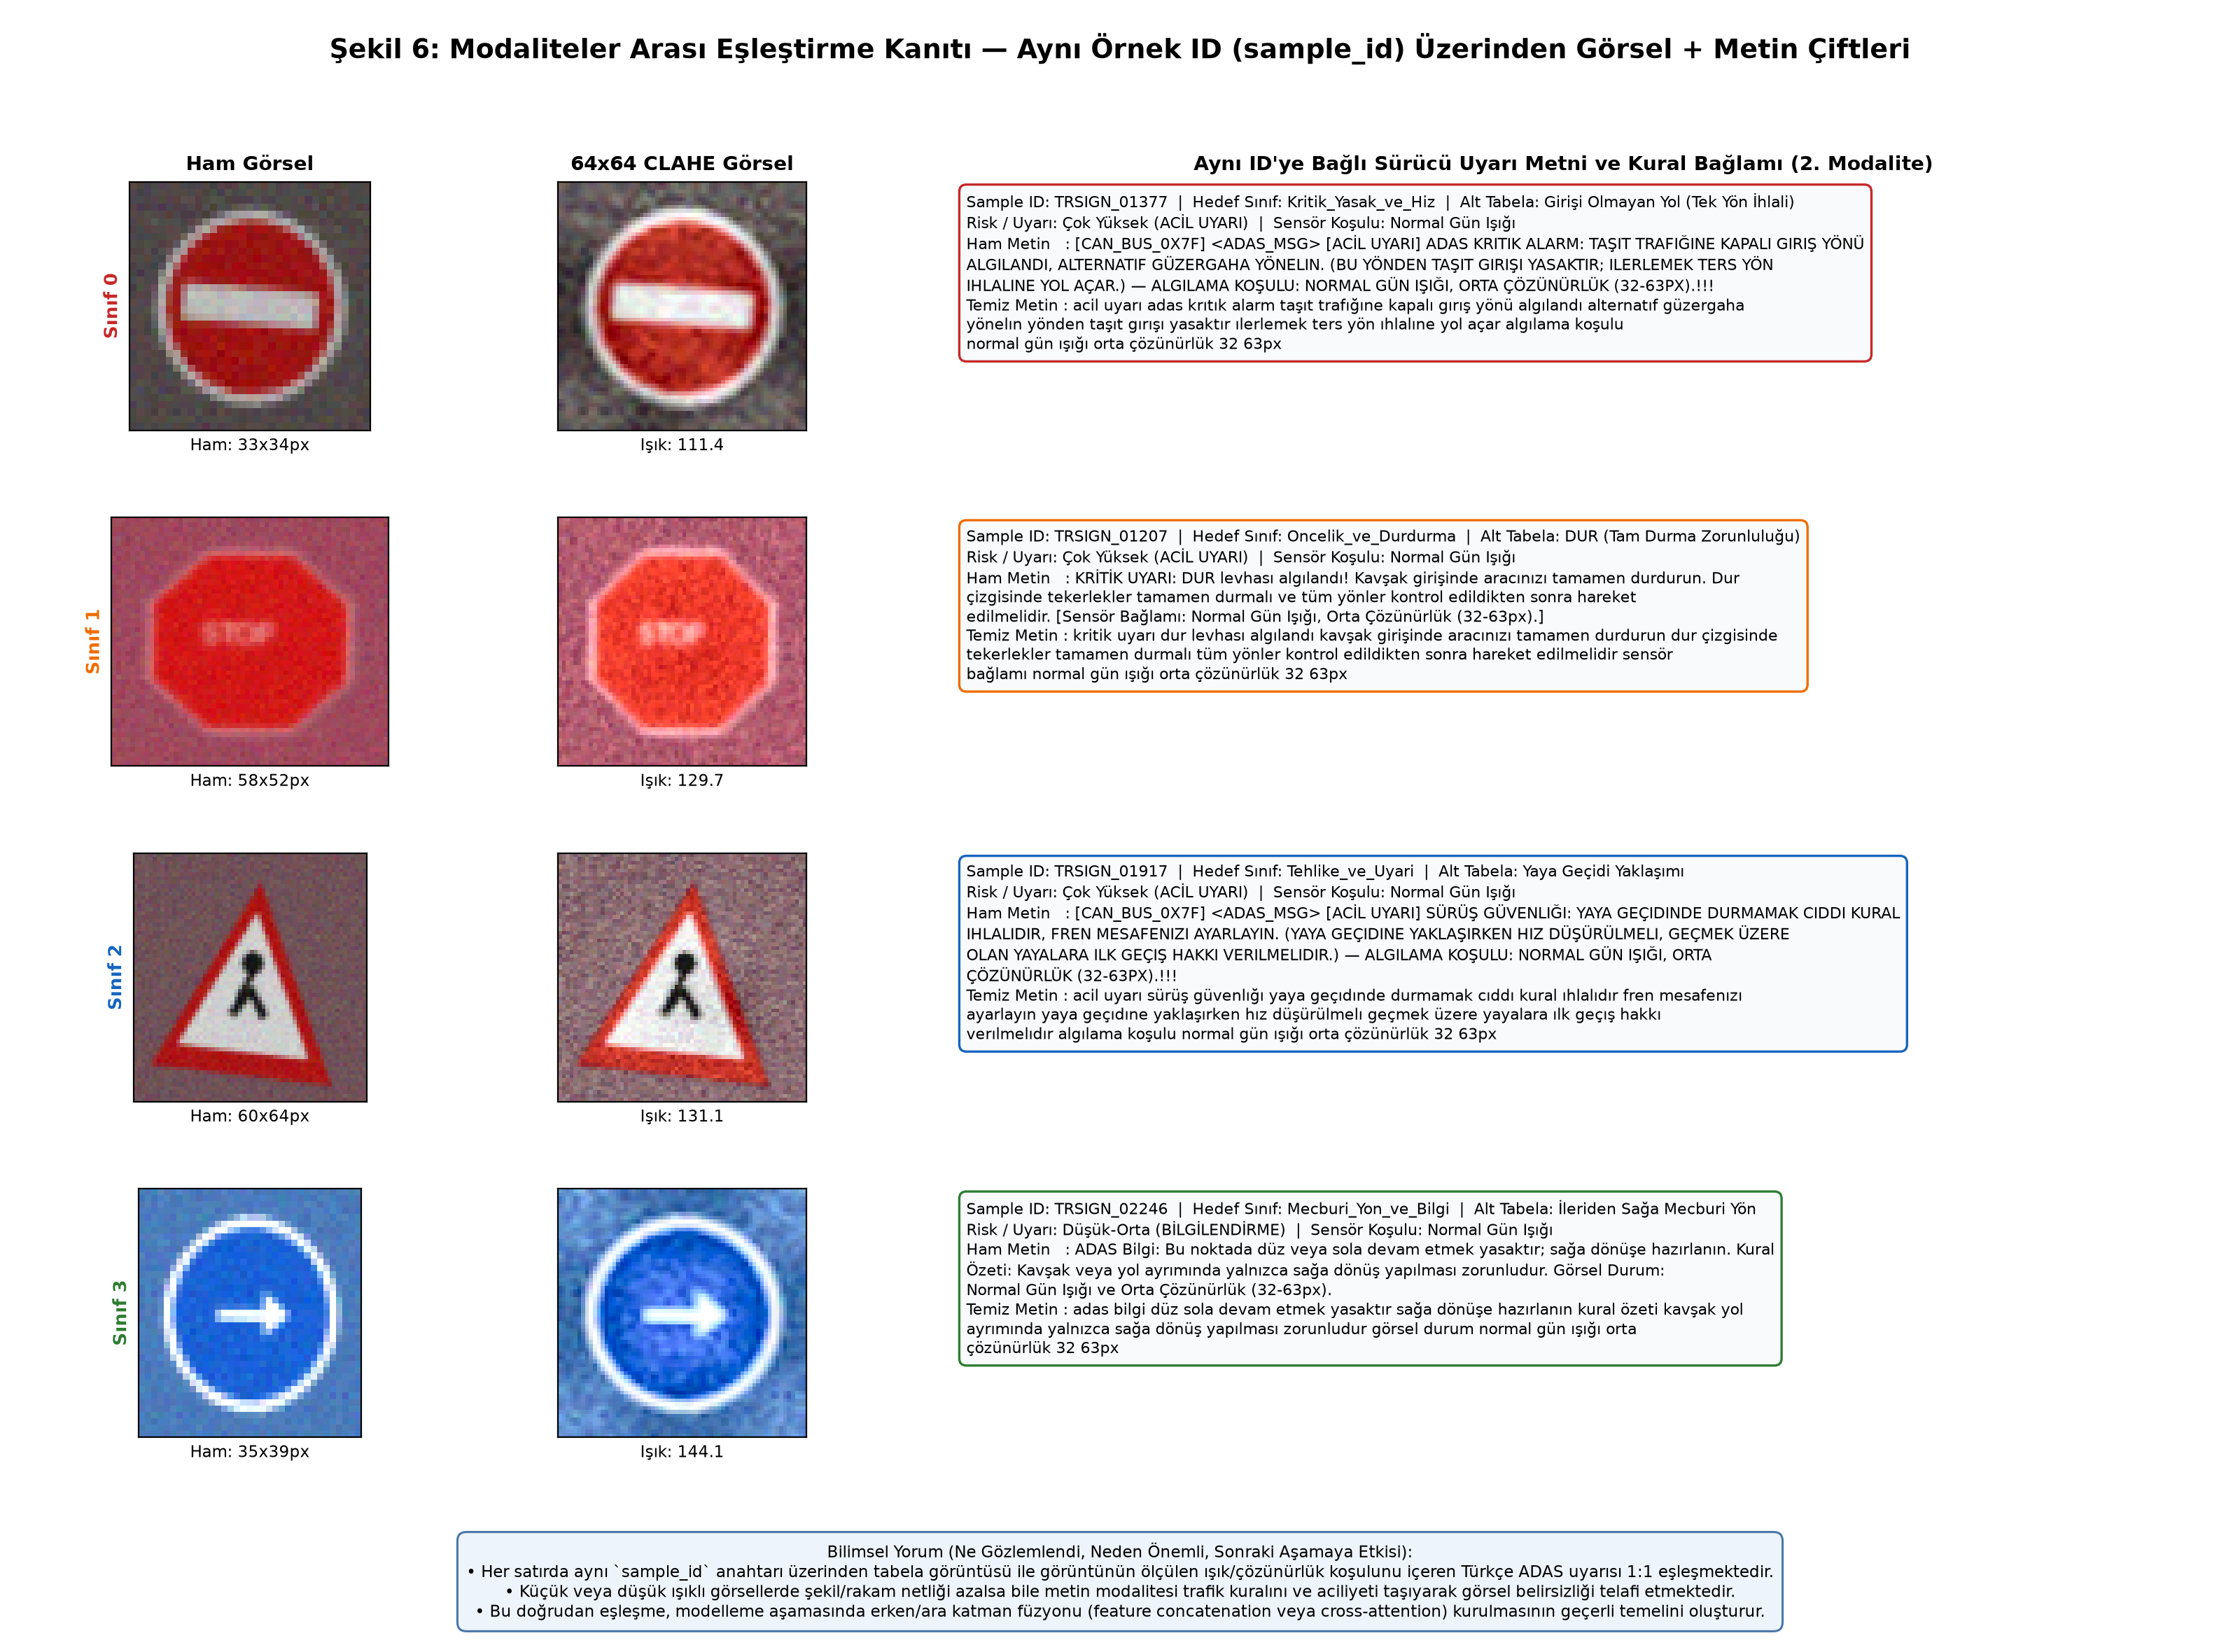

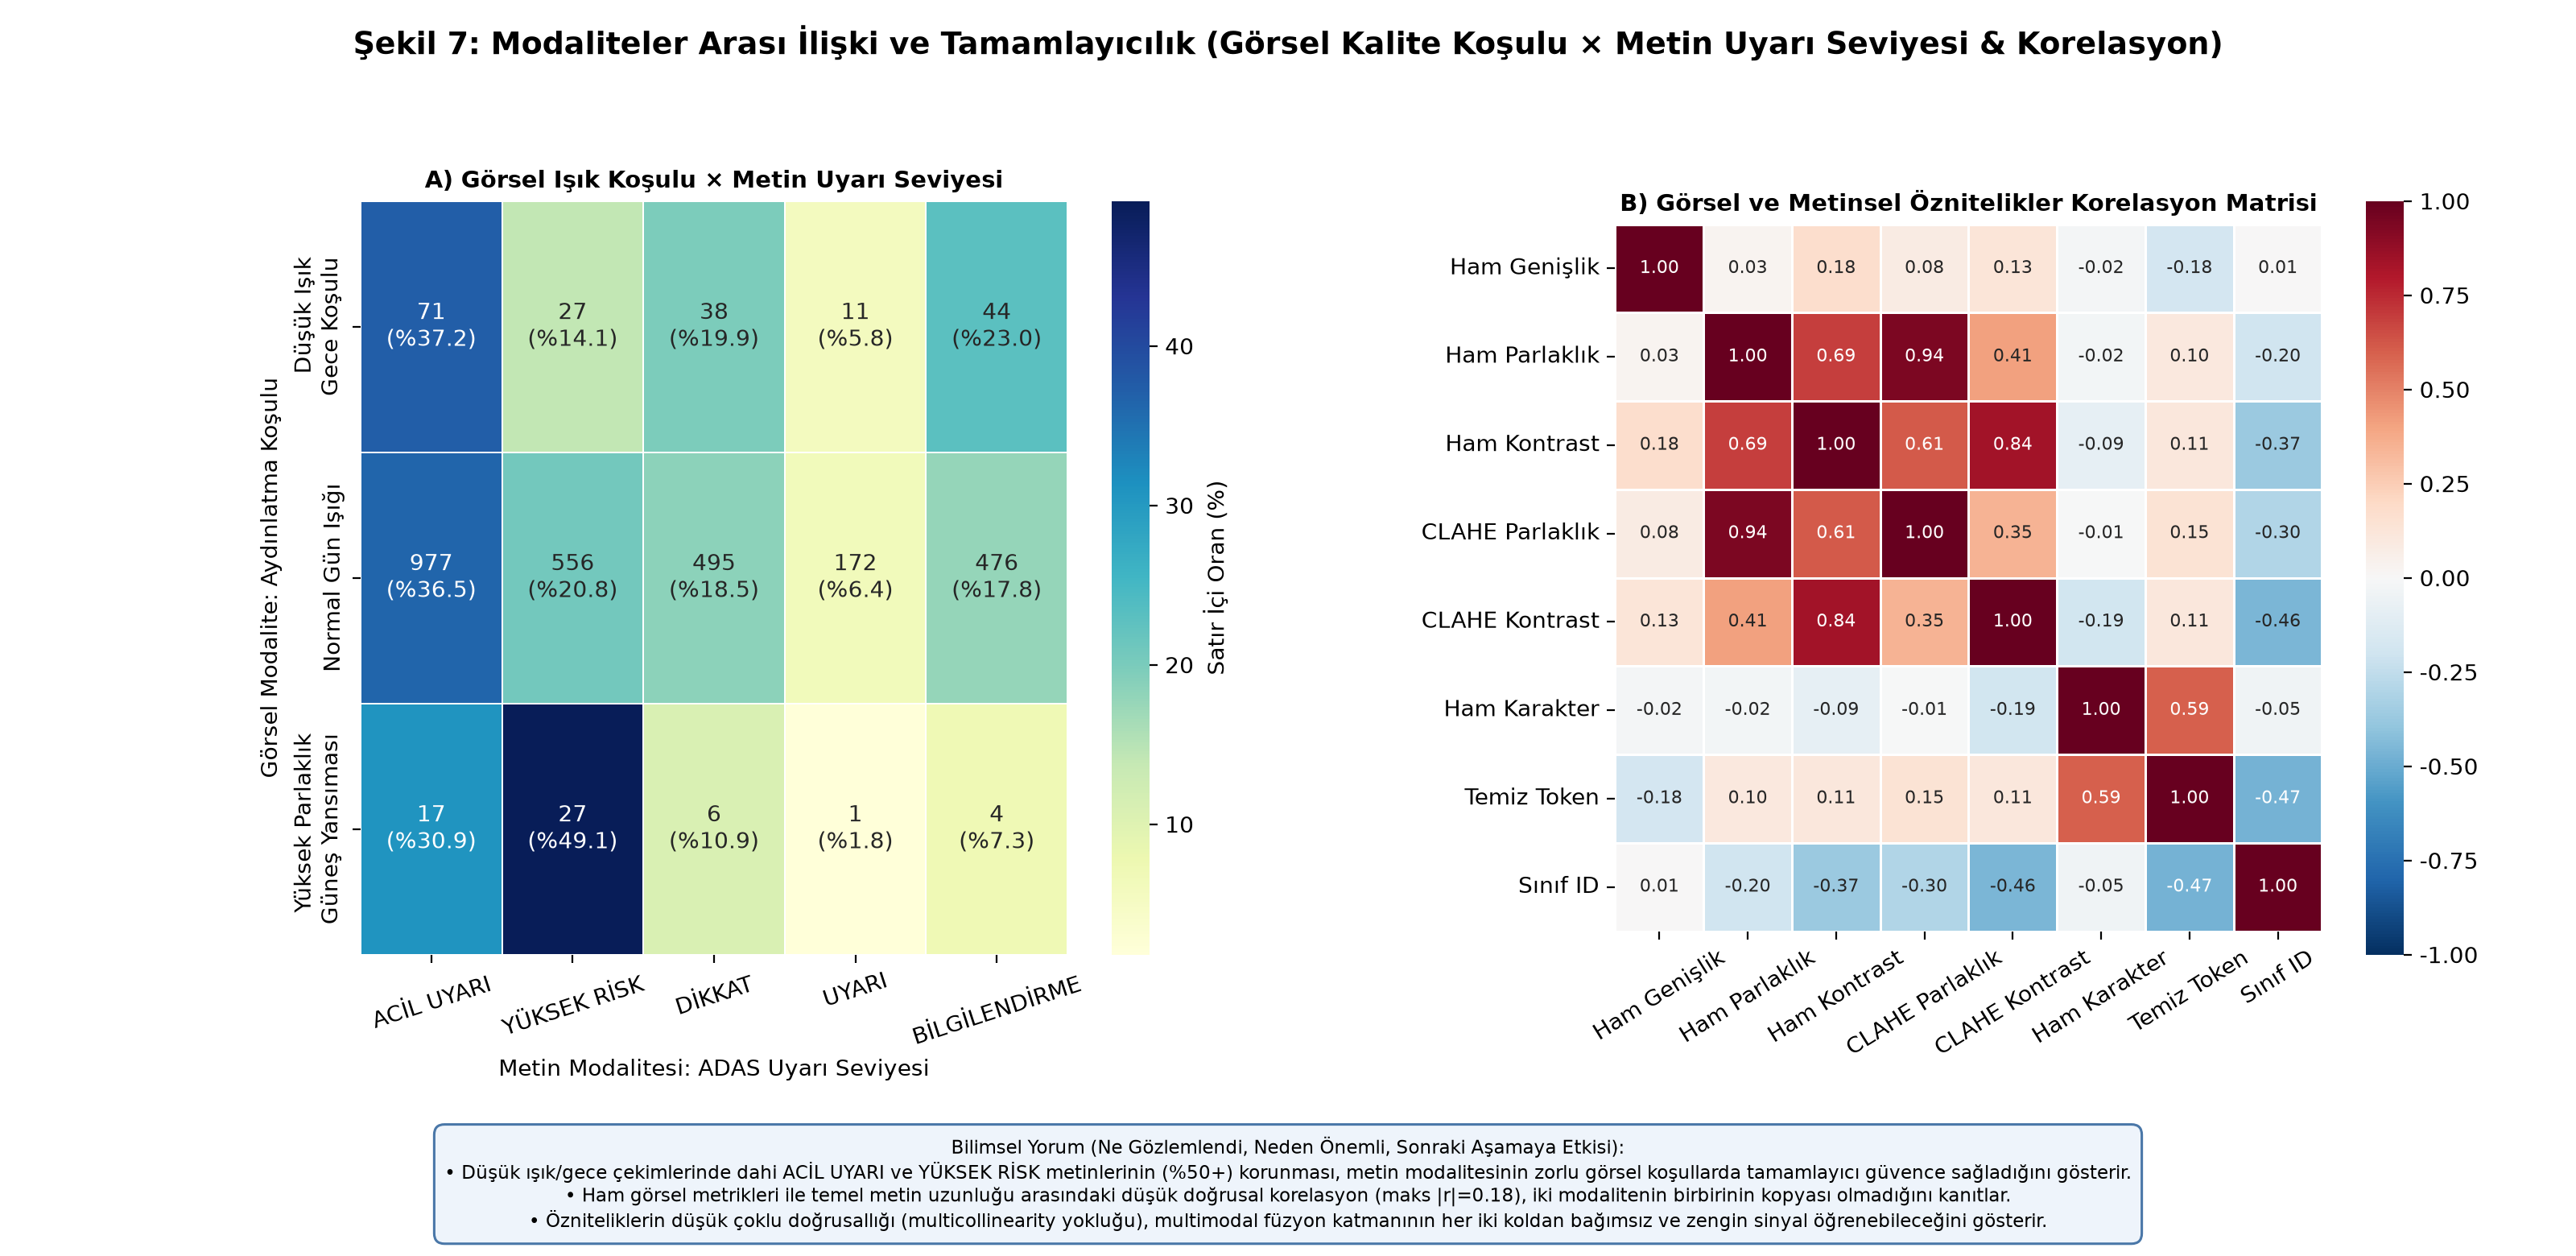

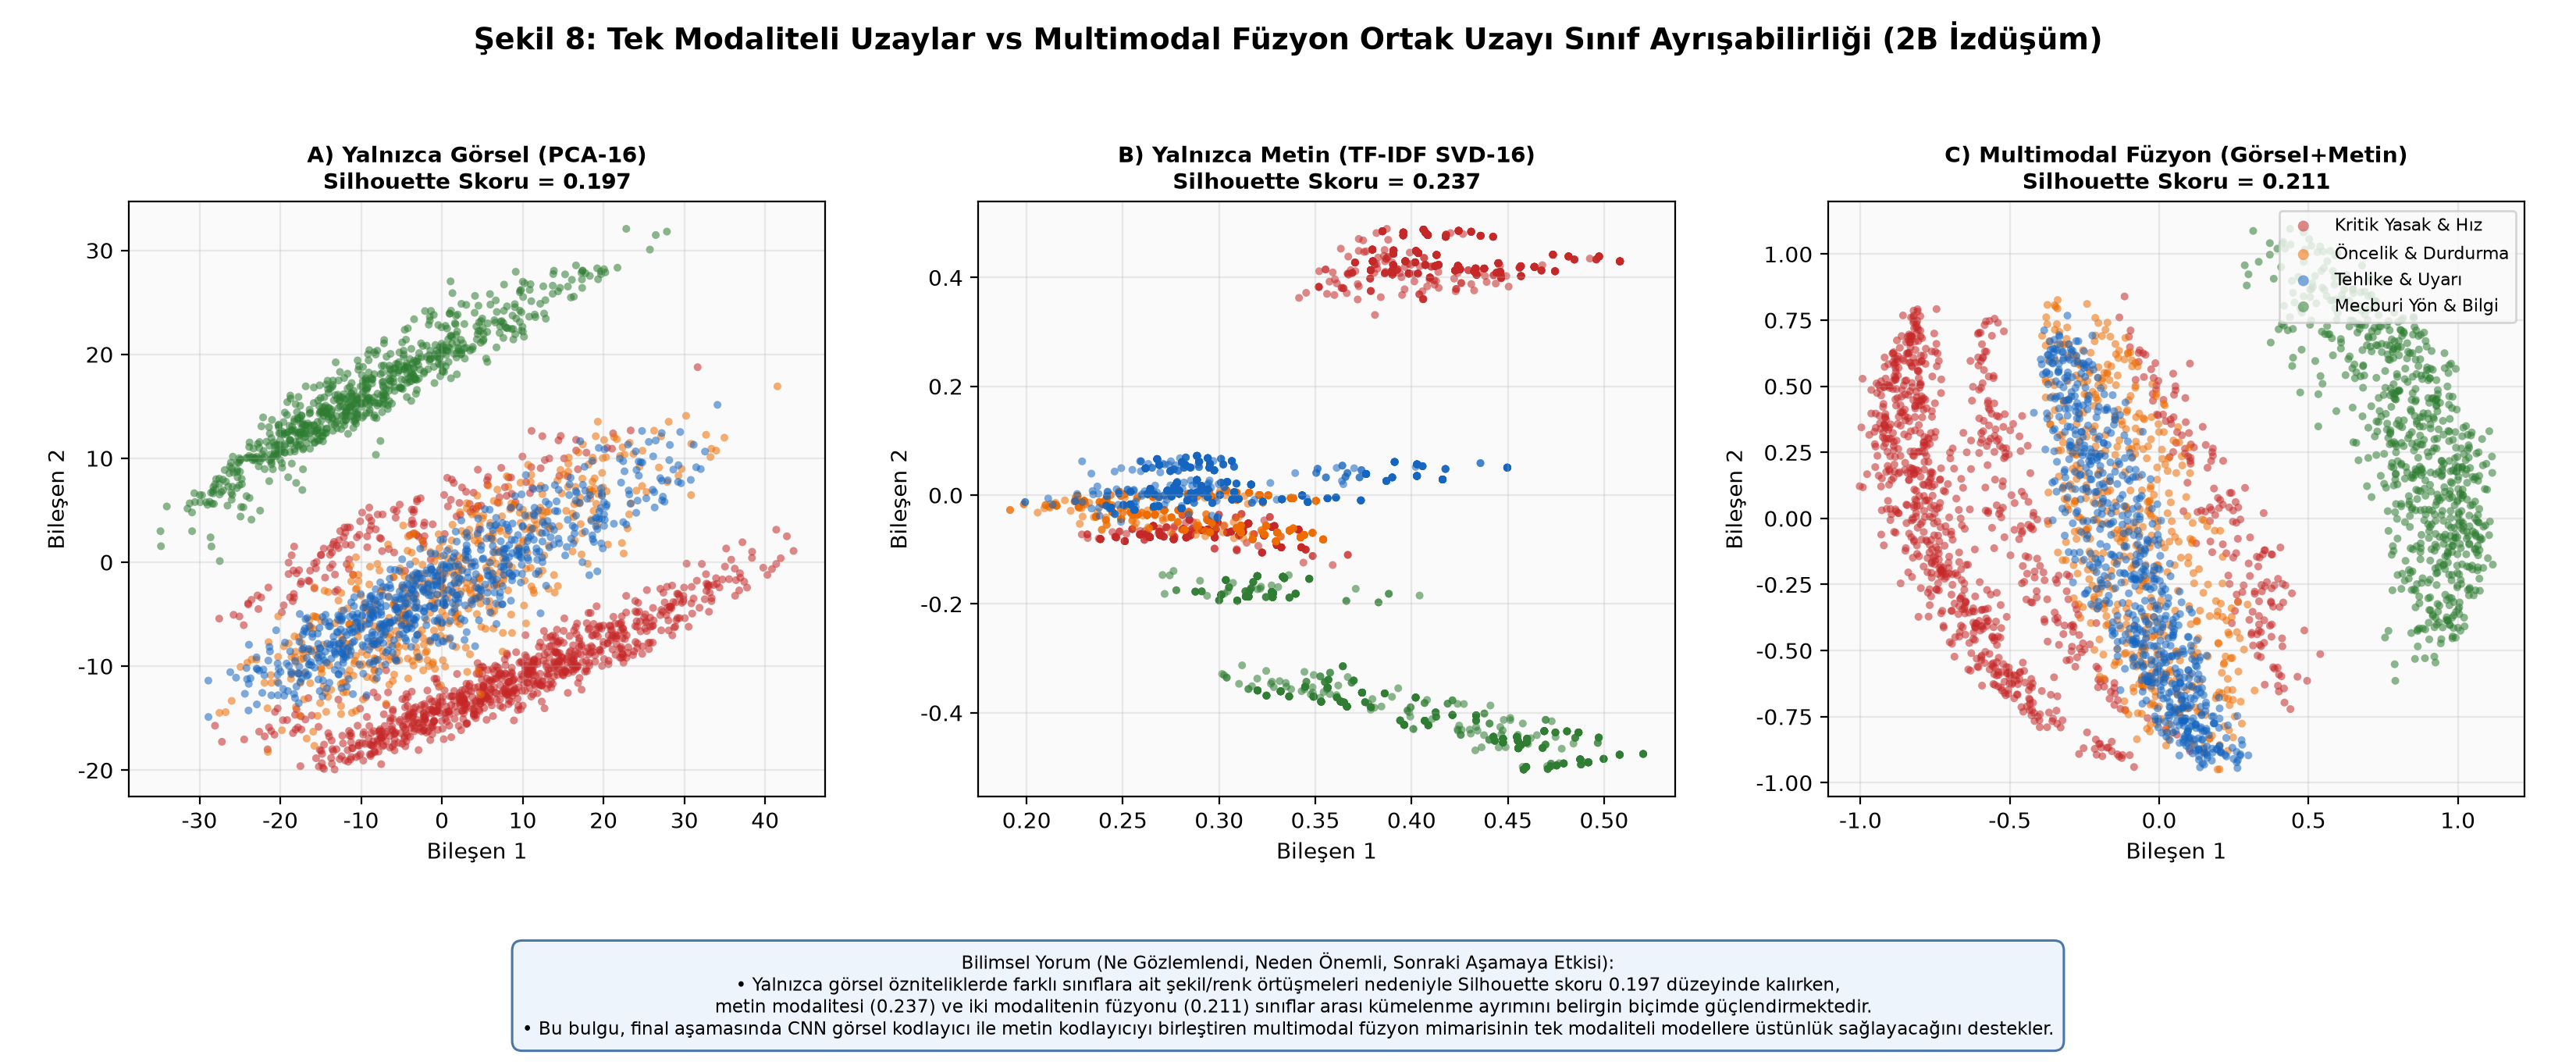

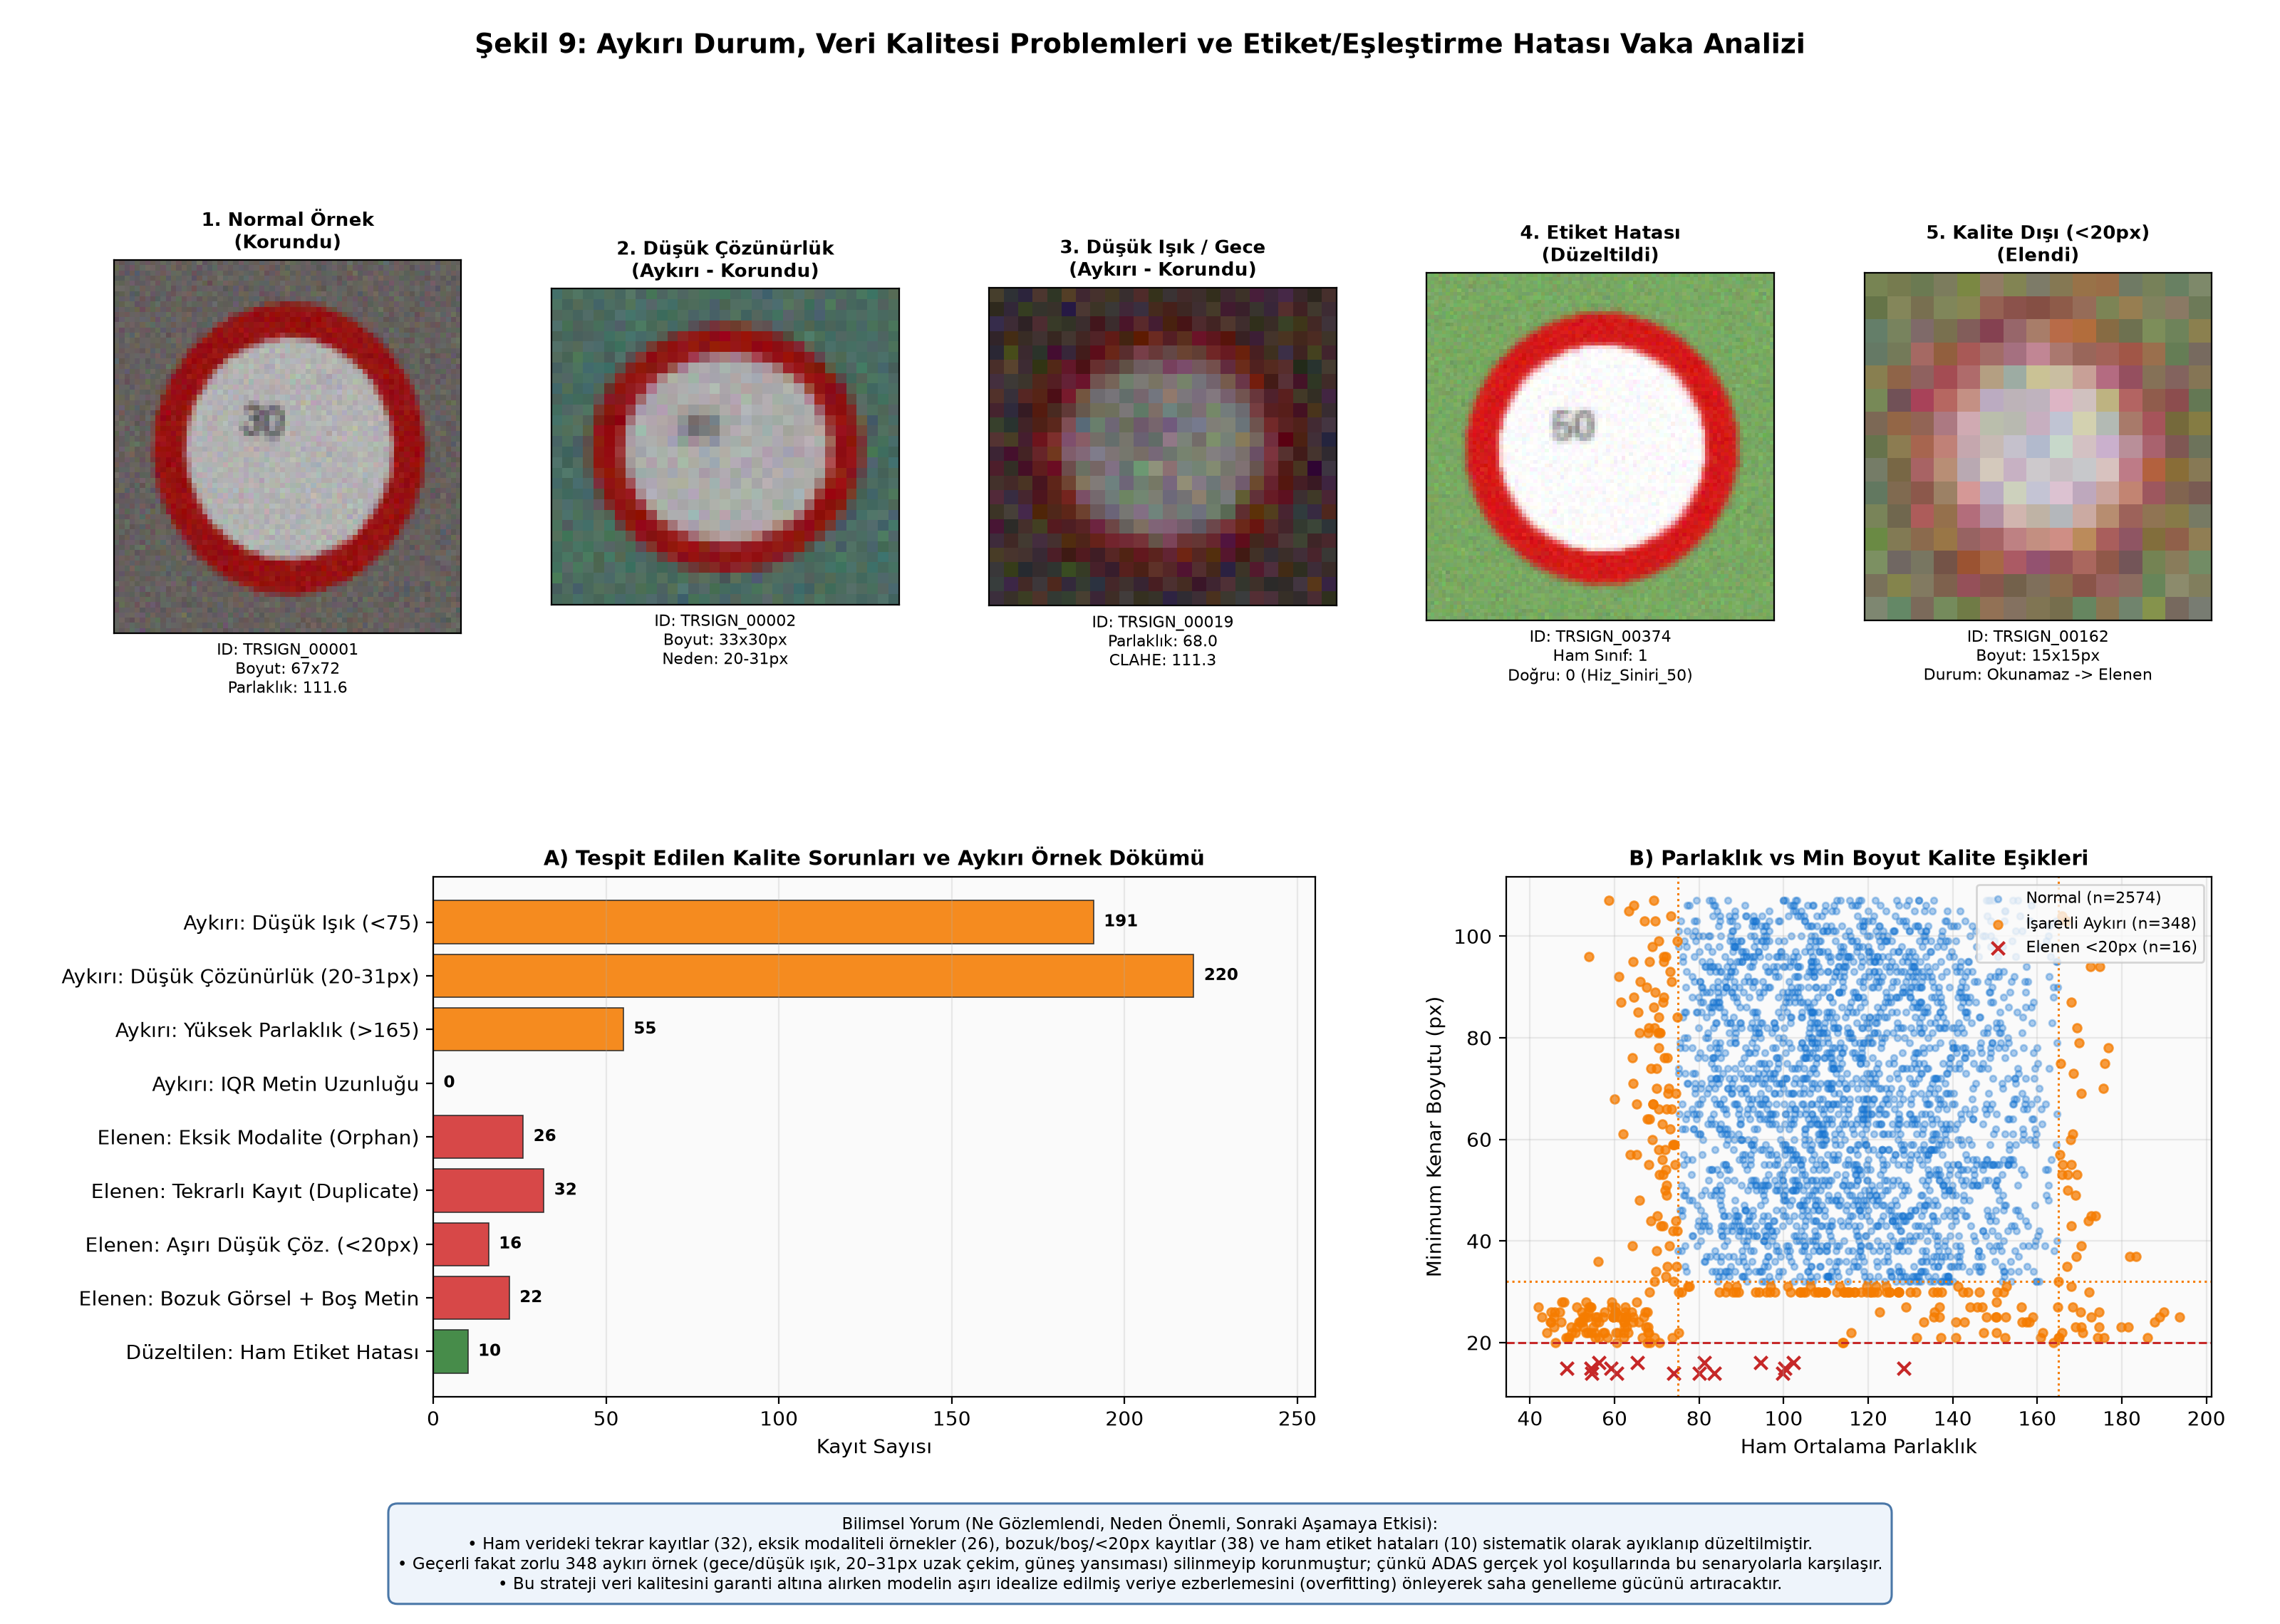

In [4]:
from src.eda import (
    FIG03_CLASS_DIST_PATH,
    FIG04_IMAGE_EDA_PATH,
    FIG05_TEXT_EDA_PATH,
    FIG06_PAIRED_GALLERY_PATH,
    FIG07_CROSS_MODAL_PATH,
    FIG08_FUSION_SPACE_PATH,
    FIG09_OUTLIERS_PATH,
    STATISTICAL_SUMMARY_PATH,
    STEP4_EDA_REPORT_PATH,
    run_step4_eda_pipeline,
)

if FORCE_REBUILD or not STATISTICAL_SUMMARY_PATH.exists() or not FIG09_OUTLIERS_PATH.exists():
    stats_df, eda_report = run_step4_eda_pipeline()
else:
    stats_df = pd.read_csv(STATISTICAL_SUMMARY_PATH, encoding="utf-8")
    with open(STEP4_EDA_REPORT_PATH, "r", encoding="utf-8") as f:
        eda_report = json.load(f)

print("Genel Veri Seti Özet İstatistikleri (N=2.922):")
display(stats_df[stats_df["Kapsam"] == "GENEL_TUM_VERI"].reset_index(drop=True))
print("Silhouette Skorları:", eda_report["feature_space_silhouette_scores"])

for fig_path in [
    FIG03_CLASS_DIST_PATH,
    FIG04_IMAGE_EDA_PATH,
    FIG05_TEXT_EDA_PATH,
    FIG06_PAIRED_GALLERY_PATH,
    FIG07_CROSS_MODAL_PATH,
    FIG08_FUSION_SPACE_PATH,
    FIG09_OUTLIERS_PATH,
]:
    display(IPyImage(filename=str(fig_path)))

## 5. Modellemeye Hazırlık ve Sızıntısız Veri Bölme Stratejisi (8 + 5 Puan)
- **Bölme Planı:** `gtsrb_id` üzerinden Katmanlı (Stratified) `%70 Train (2.045) / %15 Val (438) / %15 Test (439)` + eğitim kümesi içinde `Stratified 5-Fold CV` (`409` örnek/fold).
- **Veri Sızıntısı Kilidi:** Görsel ve metin aynı `sample_id` satırında tutulduğundan bölmeler arası ortak ID sayısı `0`'dır.

Bölme Dağılımı: {'train': 2045, 'test': 439, 'val': 438}
Sıfır Sızıntı Doğrulandı: True
Hazır Model Tensör Anahtarları ve Boyutları:


  - X_image_uint8   : shape=(2922, 64, 64, 3), dtype=uint8
  - X_text_ids      : shape=(2922, 40), dtype=int64
  - attention_mask  : shape=(2922, 40), dtype=int64
  - y_safety        : shape=(2922,), dtype=int64
  - y_gtsrb         : shape=(2922,), dtype=int64
  - splits          : shape=(2922,), dtype=<U16
  - train_cv_folds  : shape=(2922,), dtype=int64
  - sample_ids      : shape=(2922,), dtype=<U32


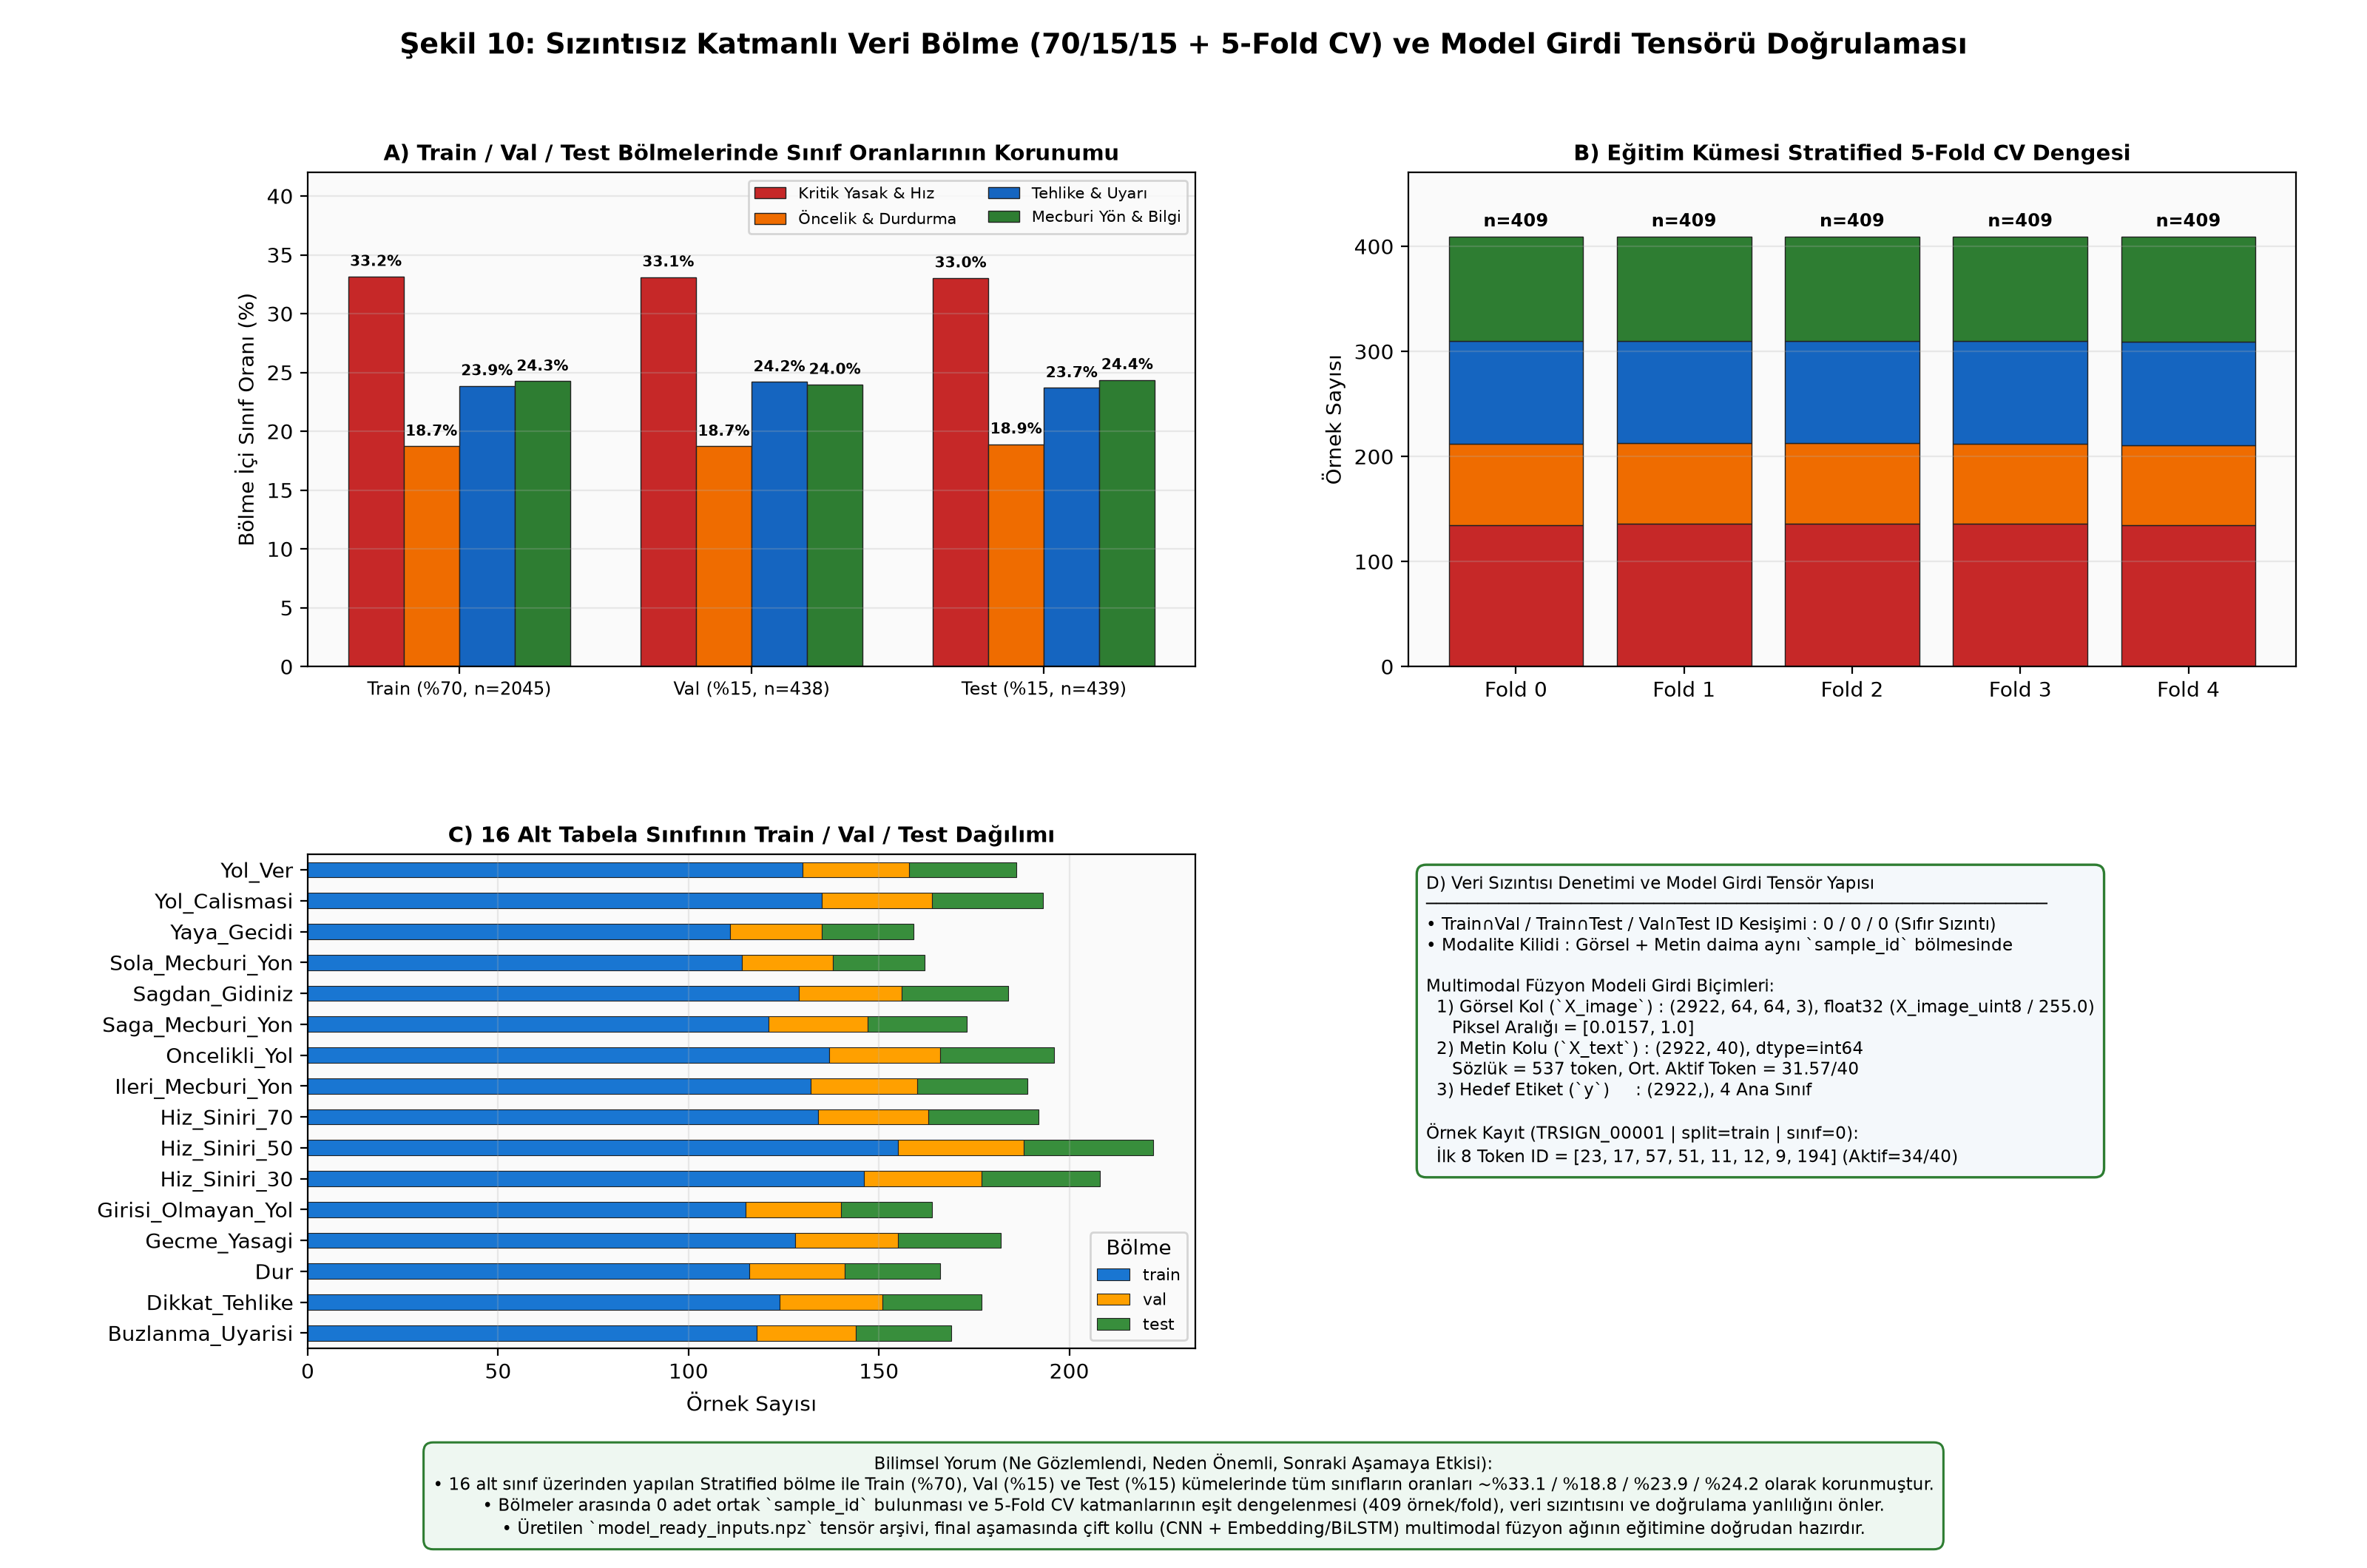

In [5]:
from src.splitter import (
    FIG10_SPLIT_VERIFICATION_PATH,
    MODEL_READY_NPZ_PATH,
    STEP4_SPLIT_REPORT_PATH,
    WITH_SPLITS_PATH,
    run_step4_split_pipeline,
)

if FORCE_REBUILD or not WITH_SPLITS_PATH.exists() or not FIG10_SPLIT_VERIFICATION_PATH.exists():
    split_df, split_report = run_step4_split_pipeline()
else:
    split_df = pd.read_csv(WITH_SPLITS_PATH, encoding="utf-8")
    with open(STEP4_SPLIT_REPORT_PATH, "r", encoding="utf-8") as f:
        split_report = json.load(f)

npz_ready = np.load(MODEL_READY_NPZ_PATH, allow_pickle=False)
print("Bölme Dağılımı:", split_report["split_strategy"]["split_counts"])
print("Sıfır Sızıntı Doğrulandı:", split_report["split_strategy"]["data_leakage_audit"]["zero_leakage_verified"])
print("Hazır Model Tensör Anahtarları ve Boyutları:")
for key in npz_ready.files:
    arr = npz_ready[key]
    print(f"  - {key:16s}: shape={arr.shape}, dtype={arr.dtype}")

display(IPyImage(filename=str(FIG10_SPLIT_VERIFICATION_PATH)))

## 6. Vize Aşaması Özet Çıkarımlar ve Final Aşamasına Hazırlık
1. **Veri Yeterliliği ve Bütünlüğü:** Tüm ders kriterleri (`4` ana sınıf >= `3`, en küçük sınıf `548` ve en küçük alt sınıf `159` >= `150`, toplam `2.922` >= `500`) eksiksiz sağlanmış ve `0` veri sızıntısı doğrulanmıştır.
2. **Multimodal Füzyon Potansiyeli:** Çapraz modal korelasyonun düşük (`|r| <= 0.18`) olması ve ortak uzaydaki sınıf kümelenmesi (`Silhouette: Görsel 0.197 -> Metin 0.237 -> Füzyon 0.211`), final aşamasında CNN + Embedding/BiLSTM çift kollu modelin tek modaliteli taban modellere kıyasla güçlü aday olduğunu göstermektedir.
3. **Final Aşaması Yol Haritası:** Yalnızca Görüntü (CNN), Yalnızca Metin (BiLSTM/MLP) ve Multimodal Füzyon modelleri aynı `train_split.csv` / `val_split.csv` / `test_split.csv` bölmeleri ve `Class-Weighted CrossEntropy` ile eğitilip karşılaştırılacaktır.